In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

c:\Users\bruno\anaconda3\envs\experimental\Lib\site-packages\seaborn\_statistics.py:32: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.1)
  from scipy.stats import gaussian_kde


In [3]:

root = os.getcwd()
folder = 'May25_Aug25_Nov25'
file = 'NAL_Filters REPORT_2026_02_20_edit.xlsx'
sheetname = 'resumed-ppm' # 'resumed-rate'
df_orig = pd.read_excel(os.path.join(root, folder,file), sheet_name=sheetname)
df_orig


,Sample ID,Season,Dust sampler_ID,Transect,LatDecimal,LonDecimal,LatDMS,LonDMS,distance,check ID,...,[Ce] (ppb),[Co] (ppb),[Cr] (ppb),[Cu] (ppb),[Li] (ppb),[Nb] (ppb),[Pb] (ppb),[Rb] (ppb),[Tl] (ppb),[V] (ppb)
0,SA-1A-W24,Winter 2024,SA-1A,1,48.420833,-77.835833,48°25′15″,-77°50′9″,0,SA-1A-W24,...,35.840804,18.970530,193.851385,86.265748,341.341882,10.759476,12.637742,376.978013,2.825006,108.354227
1,SA-1B-W24,Winter 2024,SA-1B,1,48.421944,-77.836389,48°25′19″,-77°50′11″,50,SA-1B-W24,...,8.916619,5.826382,95.741806,47.572185,233.428202,4.696257,5.946764,236.361473,1.559394,32.233836
2,SA-1C-W24,Winter 2024,SA-1C,1,48.422500,-77.837222,48°25′21″,-77°50′14″,200,SA-1C-W24,...,5.071719,3.557043,55.992662,23.737748,139.460222,2.831953,2.251580,148.790741,1.129325,17.023785
3,SA-1D-W24,Winter 2024,SA-1D,1,48.423889,-77.840556,48°25′26″,-77°50′26″,500,SA-1D-W24,...,3.761075,1.850280,21.624400,16.733698,67.193254,1.280460,3.170979,60.391689,0.257287,12.251061
4,SA-2A-W24,Winter 2024,SA-2A,2,48.410556,-77.803056,48°24′38″,-77°48′11″,0,SA-2A-W24,...,46.704500,66.785153,919.333001,277.148603,1356.550026,35.603081,26.553747,1732.142402,11.938989,236.413092
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,SA-REF-1-F25,Fall 2025,SA-REF-1,Ref_background,48.425556,-77.875278,48°25′32″,-77°52′31″,0,SA-REF-1-F25,...,-0.046055,-0.976424,2.434020,-0.380618,4.226285,-0.059636,-0.373109,2.013532,-0.108814,-0.012278
80,SA-REF-2-F25,Fall 2025,SA-REF-2,Ref_background,48.414444,-77.885278,48°24′52″,-77°53′7″,0,SA-REF-2-F25,...,0.125601,-0.947722,1.541798,-0.694546,-9.577349,-0.108823,-0.394719,1.331827,-0.114651,0.697595
81,SA-REF-3-F25,Fall 2025,SA-REF-3,Ref_background,48.390000,-77.801389,48°23′24″,-77°48′5″,0,SA-REF-3-F25,...,1.017934,-3.104965,9.051924,-0.441646,22.066714,-0.069198,0.128690,30.069312,0.072051,3.275753
82,SA-REF-4-F25,Fall 2025,SA-REF-4,Ref_internal,48.406944,-77.830556,48°24′25″,-77°49′50″,0,SA-REF-4-F25,...,8.489800,5.399281,80.963150,19.244988,600.528396,11.669676,1382.226589,500.923228,3.671104,26.797580


In [4]:
# plot ref values in histograms too, check if ref 3 is valid as background, value-wise and geo-wise

In [5]:
df_orig.shape

(84, 53)

# Renaming colums

In [6]:
import re

def keep_ppb_over_ppm(columns):
    # dictionary to store best column name per element
    selected_cols = {}

    for col in columns:
        # match patterns like:  [As] (ppm)  or  [As] (ppb)
        m = re.match(r'\[(.+?)\]\s*\((ppb|ppm)\)', col)
        
        if m:
            element = m.group(1)
            unit = m.group(2)

            # if element not seen → store directly
            if element not in selected_cols:
                selected_cols[element] = col

            else:
                # existing is ppm, new is ppb → replace
                existing = selected_cols[element]
                if "ppm" in existing and unit == "ppb":
                    selected_cols[element] = col

        else:
            # keep non-matching columns
            selected_cols[col] = col

    # return dataframe with selected columns only
    return selected_cols.values()


In [7]:
df = df_orig.copy()

In [8]:
df.columns = df.columns.str.strip(' ')

In [ ]:
remove this feature, keep them separated - for streamlit, add an option to plot aes or icp-ms - maybe keep the feature but as a 3rd option

filter = keep_ppb_over_ppm(df.columns)
filter

dict_values(['Sample ID', 'Season', 'Dust sampler_ID', 'Transect', 'LatDecimal', 'LonDecimal', 'LatDMS', 'LonDMS', 'distance', 'check ID', 'Change in mass (mg)', '(mg/dm2/day)', '[Al] (ppm)', '[As] (ppb)', '[Ba] (ppb)', '[Bi] (ppm)', '[Ca] (ppm)', '[Cd] (ppm)', '[Co] (ppb)', '[Cr] (ppb)', '[Cu] (ppb)', '[Fe] (ppm)', '[K] (ppm)', '[Li] (ppb)', '[Mg] (ppm)', '[Mn] (ppm)', '[Mo] (ppm)', '[Na] (ppm)', '[Ni] (ppm)', '[P] (ppm)', '[Pb] (ppb)', '[S (ICP)] (ppm)', '[Sb] (ppm)', '[Se] (ppm)', '[Si] (ppm)', '[Sr] (ppm)', '[Ti] (ppm)', '[V] (ppb)', '[Zn] (ppm)', '[Zr] (ppm)', '[Be] (ppb)', '[Ce] (ppb)', '[Nb] (ppb)', '[Rb] (ppb)', '[Tl] (ppb)'])

In [10]:
df = df.loc[:,filter]
df

,Sample ID,Season,Dust sampler_ID,Transect,LatDecimal,LonDecimal,LatDMS,LonDMS,distance,check ID,...,[Sr] (ppm),[Ti] (ppm),[V] (ppb),[Zn] (ppm),[Zr] (ppm),[Be] (ppb),[Ce] (ppb),[Nb] (ppb),[Rb] (ppb),[Tl] (ppb)
0,SA-1A-W24,Winter 2024,SA-1A,1,48.420833,-77.835833,48°25′15″,-77°50′9″,0,SA-1A-W24,...,0.357517,4.323584,108.354227,0.118321,0.095204,7.649300,35.840804,10.759476,376.978013,2.825006
1,SA-1B-W24,Winter 2024,SA-1B,1,48.421944,-77.836389,48°25′19″,-77°50′11″,50,SA-1B-W24,...,0.080506,1.183437,32.233836,0.038679,0.021186,5.507681,8.916619,4.696257,236.361473,1.559394
2,SA-1C-W24,Winter 2024,SA-1C,1,48.422500,-77.837222,48°25′21″,-77°50′14″,200,SA-1C-W24,...,0.045525,0.654697,17.023785,0.018585,0.010218,3.740547,5.071719,2.831953,148.790741,1.129325
3,SA-1D-W24,Winter 2024,SA-1D,1,48.423889,-77.840556,48°25′26″,-77°50′26″,500,SA-1D-W24,...,0.034486,0.471172,12.251061,0.017722,0.011153,1.134764,3.761075,1.280460,60.391689,0.257287
4,SA-2A-W24,Winter 2024,SA-2A,2,48.410556,-77.803056,48°24′38″,-77°48′11″,0,SA-2A-W24,...,0.368426,8.172379,236.413092,0.292857,0.075055,37.956021,46.704500,35.603081,1732.142402,11.938989
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,SA-REF-1-F25,Fall 2025,SA-REF-1,Ref_background,48.425556,-77.875278,48°25′32″,-77°52′31″,0,SA-REF-1-F25,...,0.001456,0.008580,-0.012278,-0.002708,0.000146,-0.454052,-0.046055,-0.059636,2.013532,-0.108814
80,SA-REF-2-F25,Fall 2025,SA-REF-2,Ref_background,48.414444,-77.885278,48°24′52″,-77°53′7″,0,SA-REF-2-F25,...,0.002412,0.011785,0.697595,0.008484,0.000122,-0.468142,0.125601,-0.108823,1.331827,-0.114651
81,SA-REF-3-F25,Fall 2025,SA-REF-3,Ref_background,48.390000,-77.801389,48°23′24″,-77°48′5″,0,SA-REF-3-F25,...,0.013447,0.222425,3.275753,0.001941,0.001141,-0.456791,1.017934,-0.069198,30.069312,0.072051
82,SA-REF-4-F25,Fall 2025,SA-REF-4,Ref_internal,48.406944,-77.830556,48°24′25″,-77°49′50″,0,SA-REF-4-F25,...,0.085455,0.794569,26.797580,0.049267,0.012146,24.035750,8.489800,11.669676,500.923228,3.671104


In [11]:
info_cols = ['Sample ID', 'Season', 'Dust sampler_ID', 'Transect','Change in mass (mg)']
df.loc[:,info_cols]

,Sample ID,Season,Dust sampler_ID,Transect,Change in mass (mg)
0,SA-1A-W24,Winter 2024,SA-1A,1,158.4
1,SA-1B-W24,Winter 2024,SA-1B,1,45.9
2,SA-1C-W24,Winter 2024,SA-1C,1,37.5
3,SA-1D-W24,Winter 2024,SA-1D,1,27.3
4,SA-2A-W24,Winter 2024,SA-2A,2,261.5
...,...,...,...,...,...
79,SA-REF-1-F25,Fall 2025,SA-REF-1,Ref_background,7.1
80,SA-REF-2-F25,Fall 2025,SA-REF-2,Ref_background,8.7
81,SA-REF-3-F25,Fall 2025,SA-REF-3,Ref_background,22.7
82,SA-REF-4-F25,Fall 2025,SA-REF-4,Ref_internal,87.9


In [12]:
cols_interest = df.columns

mask = [(cols.endswith('(ppm)') | cols.endswith('(ppb)')) for cols in cols_interest]
cols_interest = cols_interest[mask]
cols_interest

Index(['[Al] (ppm)', '[As] (ppb)', '[Ba] (ppb)', '[Bi] (ppm)', '[Ca] (ppm)',
       '[Cd] (ppm)', '[Co] (ppb)', '[Cr] (ppb)', '[Cu] (ppb)', '[Fe] (ppm)',
       '[K] (ppm)', '[Li] (ppb)', '[Mg] (ppm)', '[Mn] (ppm)', '[Mo] (ppm)',
       '[Na] (ppm)', '[Ni] (ppm)', '[P] (ppm)', '[Pb] (ppb)',
       '[S (ICP)] (ppm)', '[Sb] (ppm)', '[Se] (ppm)', '[Si] (ppm)',
       '[Sr] (ppm)', '[Ti] (ppm)', '[V] (ppb)', '[Zn] (ppm)', '[Zr] (ppm)',
       '[Be] (ppb)', '[Ce] (ppb)', '[Nb] (ppb)', '[Rb] (ppb)', '[Tl] (ppb)'],
      dtype='object')

In [13]:
mask_ppm = [cols.endswith('(ppm)') for cols in cols_interest]
mask_ppb = [cols.endswith('(ppb)') for cols in cols_interest]
ppm_cols = cols_interest[mask_ppm]
ppb_cols = cols_interest[mask_ppb]
ppm_cols, ppb_cols

(Index(['[Al] (ppm)', '[Bi] (ppm)', '[Ca] (ppm)', '[Cd] (ppm)', '[Fe] (ppm)',
        '[K] (ppm)', '[Mg] (ppm)', '[Mn] (ppm)', '[Mo] (ppm)', '[Na] (ppm)',
        '[Ni] (ppm)', '[P] (ppm)', '[S (ICP)] (ppm)', '[Sb] (ppm)',
        '[Se] (ppm)', '[Si] (ppm)', '[Sr] (ppm)', '[Ti] (ppm)', '[Zn] (ppm)',
        '[Zr] (ppm)'],
       dtype='object'),
 Index(['[As] (ppb)', '[Ba] (ppb)', '[Co] (ppb)', '[Cr] (ppb)', '[Cu] (ppb)',
        '[Li] (ppb)', '[Pb] (ppb)', '[V] (ppb)', '[Be] (ppb)', '[Ce] (ppb)',
        '[Nb] (ppb)', '[Rb] (ppb)', '[Tl] (ppb)'],
       dtype='object'))

In [14]:
# new_ppm_cols =[cols.split(' ')[0].split('[')[1].split(']')[0]+'_ppm' for cols in ppm_cols]
# for (new_col, old_col) in zip(new_ppm_cols,ppm_cols):
# 	df[new_col] = df[old_col]

In [15]:
# new_ppb_cols = [cols.split(' ')[0].split('[')[1].split(']')[0]+'_ppm' for cols in ppb_cols]
# for (new_col, old_col) in zip(new_ppb_cols,ppb_cols):
# 	df[new_col] = df[old_col] / 1000


# Dealing with LODS

There is a lot going on in NRCan's spreadsheet, including dealing with LOD. But the final output considering the sample weight seems to output negatives for below detection limits. For now I'll just set them to a very small value.

In [16]:
cols_interest

Index(['[Al] (ppm)', '[As] (ppb)', '[Ba] (ppb)', '[Bi] (ppm)', '[Ca] (ppm)',
       '[Cd] (ppm)', '[Co] (ppb)', '[Cr] (ppb)', '[Cu] (ppb)', '[Fe] (ppm)',
       '[K] (ppm)', '[Li] (ppb)', '[Mg] (ppm)', '[Mn] (ppm)', '[Mo] (ppm)',
       '[Na] (ppm)', '[Ni] (ppm)', '[P] (ppm)', '[Pb] (ppb)',
       '[S (ICP)] (ppm)', '[Sb] (ppm)', '[Se] (ppm)', '[Si] (ppm)',
       '[Sr] (ppm)', '[Ti] (ppm)', '[V] (ppb)', '[Zn] (ppm)', '[Zr] (ppm)',
       '[Be] (ppb)', '[Ce] (ppb)', '[Nb] (ppb)', '[Rb] (ppb)', '[Tl] (ppb)'],
      dtype='object')

In [17]:

df = df.rename(columns={'Transect ': 'Transect'})

In [18]:

for col in cols_interest:
    # Get the minimum value of the current column
    min_val = df.loc[df[col] > 0, col].min()
    
    # Calculate the replacement value: Min_Value / sqrt(2)
    replacement_value = min_val / np.sqrt(2)
    
    # Use boolean indexing to replace the negative values in the column
    df.loc[df[col] < 0, col] = replacement_value
    
    # Optional: Print the calculated value for verification
    print(f"Column '{col}': Min={min_val}, Replacement Value={replacement_value:.4f}")

print("-" * 30)
print("Modified DataFrame:")
df.head()

Column '[Al] (ppm)': Min=0.3624409850642784, Replacement Value=0.2563
Column '[As] (ppb)': Min=0.0033928341956259126, Replacement Value=0.0024
Column '[Ba] (ppb)': Min=0.13241064142106257, Replacement Value=0.0936
Column '[Bi] (ppm)': Min=7.197827257908206e-06, Replacement Value=0.0000
Column '[Ca] (ppm)': Min=0.24938713944266377, Replacement Value=0.1763
Column '[Cd] (ppm)': Min=0.0004628635640534045, Replacement Value=0.0003
Column '[Co] (ppb)': Min=0.1279639081455484, Replacement Value=0.0905
Column '[Cr] (ppb)': Min=1.5417979187571742, Replacement Value=1.0902
Column '[Cu] (ppb)': Min=0.22624495423913665, Replacement Value=0.1600
Column '[Fe] (ppm)': Min=0.18583507802788912, Replacement Value=0.1314
Column '[K] (ppm)': Min=0.0015743312483921512, Replacement Value=0.0011
Column '[Li] (ppb)': Min=2.7345656371665283, Replacement Value=1.9336
Column '[Mg] (ppm)': Min=0.12991252136060438, Replacement Value=0.0919
Column '[Mn] (ppm)': Min=0.0069592053477888285, Replacement Value=0.0049
C

,Sample ID,Season,Dust sampler_ID,Transect,LatDecimal,LonDecimal,LatDMS,LonDMS,distance,check ID,...,[Sr] (ppm),[Ti] (ppm),[V] (ppb),[Zn] (ppm),[Zr] (ppm),[Be] (ppb),[Ce] (ppb),[Nb] (ppb),[Rb] (ppb),[Tl] (ppb)
0,SA-1A-W24,Winter 2024,SA-1A,1,48.420833,-77.835833,48°25′15″,-77°50′9″,0,SA-1A-W24,...,0.357517,4.323584,108.354227,0.118321,0.095204,7.649300,35.840804,10.759476,376.978013,2.825006
1,SA-1B-W24,Winter 2024,SA-1B,1,48.421944,-77.836389,48°25′19″,-77°50′11″,50,SA-1B-W24,...,0.080506,1.183437,32.233836,0.038679,0.021186,5.507681,8.916619,4.696257,236.361473,1.559394
2,SA-1C-W24,Winter 2024,SA-1C,1,48.422500,-77.837222,48°25′21″,-77°50′14″,200,SA-1C-W24,...,0.045525,0.654697,17.023785,0.018585,0.010218,3.740547,5.071719,2.831953,148.790741,1.129325
3,SA-1D-W24,Winter 2024,SA-1D,1,48.423889,-77.840556,48°25′26″,-77°50′26″,500,SA-1D-W24,...,0.034486,0.471172,12.251061,0.017722,0.011153,1.134764,3.761075,1.280460,60.391689,0.257287
4,SA-2A-W24,Winter 2024,SA-2A,2,48.410556,-77.803056,48°24′38″,-77°48′11″,0,SA-2A-W24,...,0.368426,8.172379,236.413092,0.292857,0.075055,37.956021,46.704500,35.603081,1732.142402,11.938989


In [19]:
10/25

0.4

# Histograms

In [21]:
def multiple_hist(dataframe, cols_interest,log=False, n_cols = 4,n_bins = None):


	n_rows = int(np.ceil(len(cols_interest) / n_cols))

	fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 3*n_rows))
	axes = axes.flatten()  # make iterable

	for i, column in enumerate(cols_interest):
		array = dataframe[column].dropna()
		if log:
			array = np.log10(array)

		if n_bins is None:
				n_bins = len(array) // 3

		freq, bin_edges = np.histogram(array, bins=n_bins)

		axes[i].hist(array, bins=n_bins, edgecolor="k")
		axes[i].vlines(array.median(), ymin=0, ymax=freq.max(), color='r', label='Median')
		axes[i].vlines(array.mean(), ymin=0, ymax=freq.max(), color='k', label='Mean')
		axes[i].set_title(f"{column}")
		axes[i].grid(True)

	# Remove unused subplots if n_sets < n_rows*n_cols
	for j in range(i+1, len(axes)):
		fig.delaxes(axes[j])

	plt.tight_layout()
	plt.show()




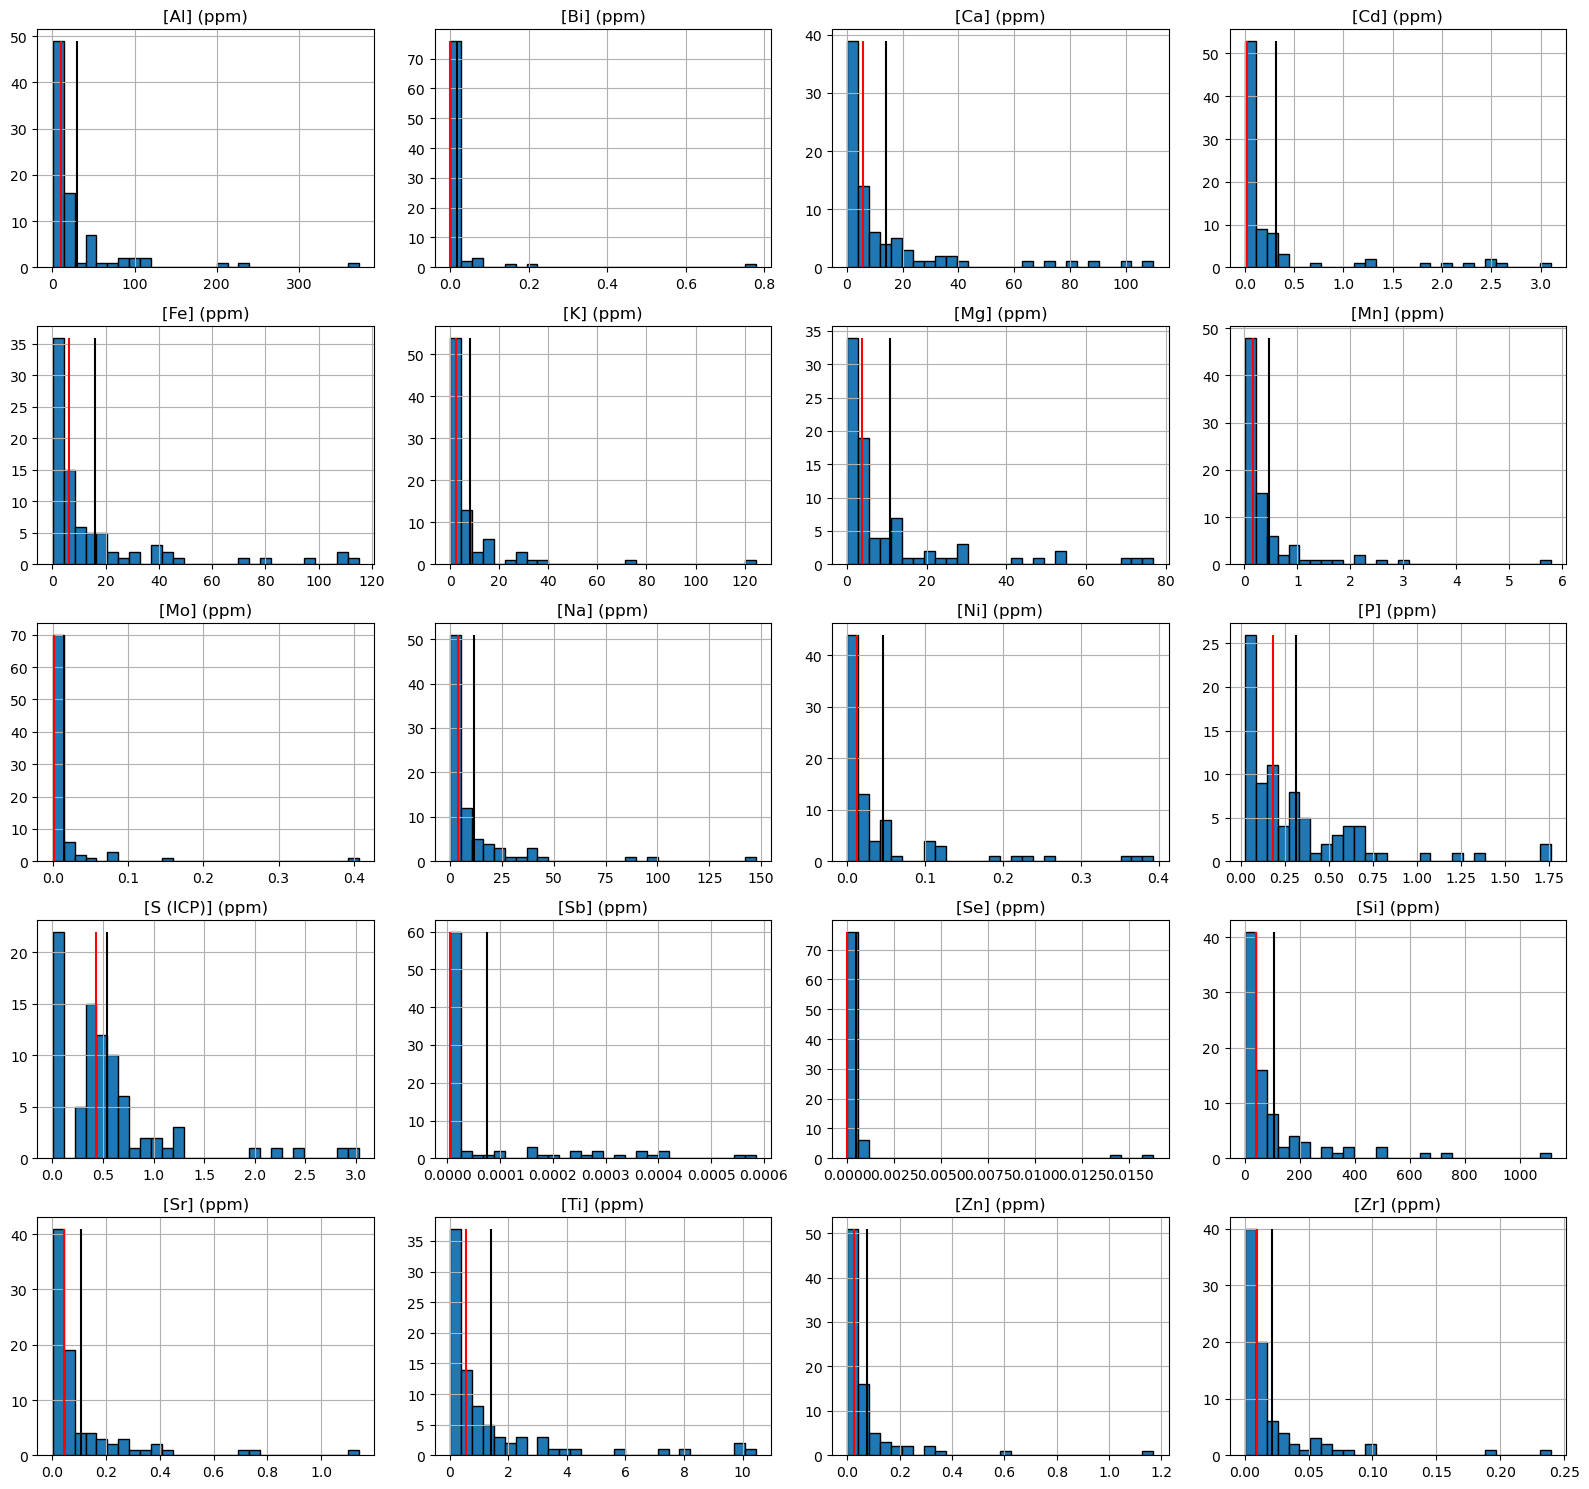

In [22]:
multiple_hist(df,ppm_cols)

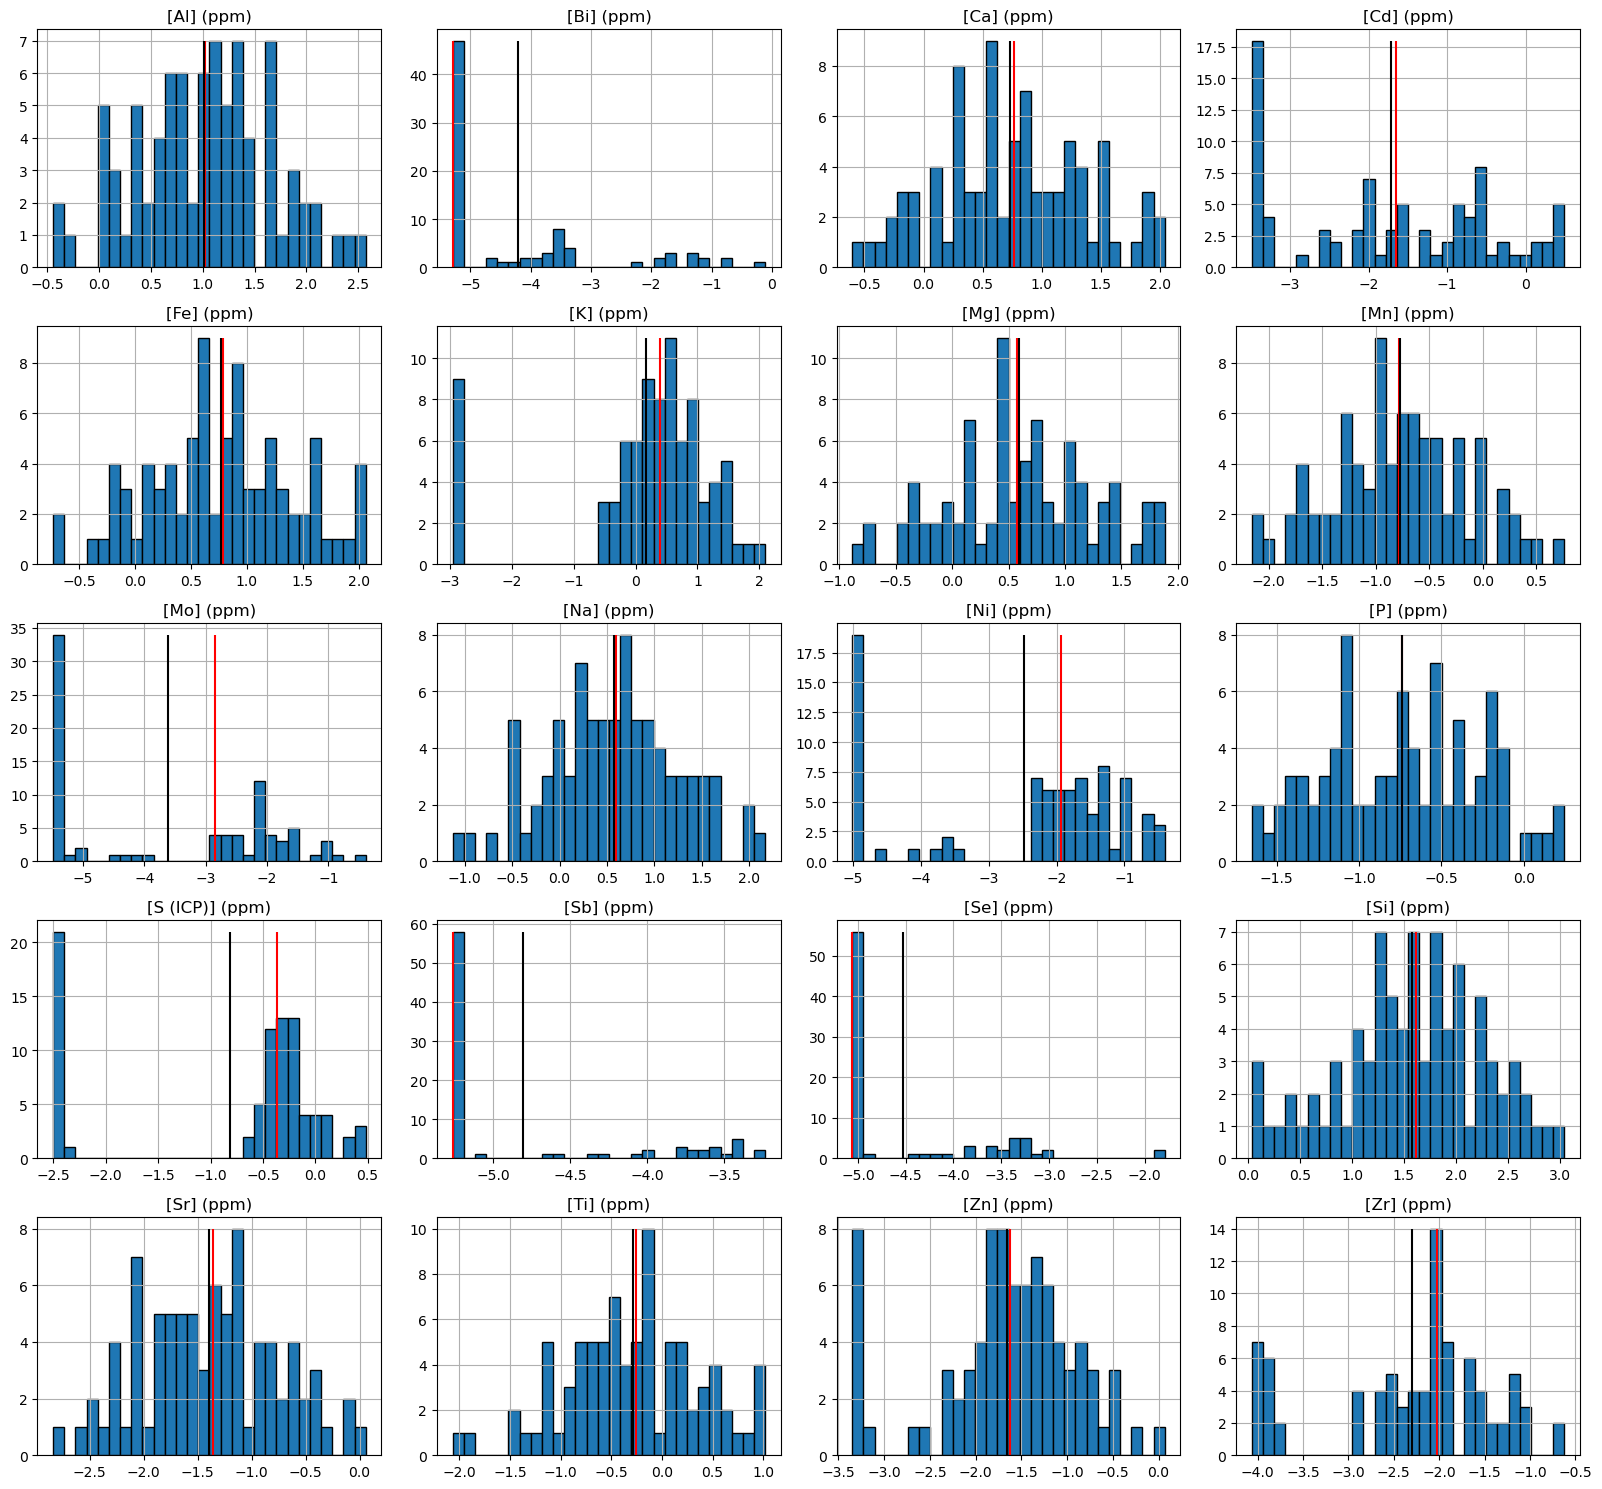

In [23]:
multiple_hist(df,ppm_cols,log=True)

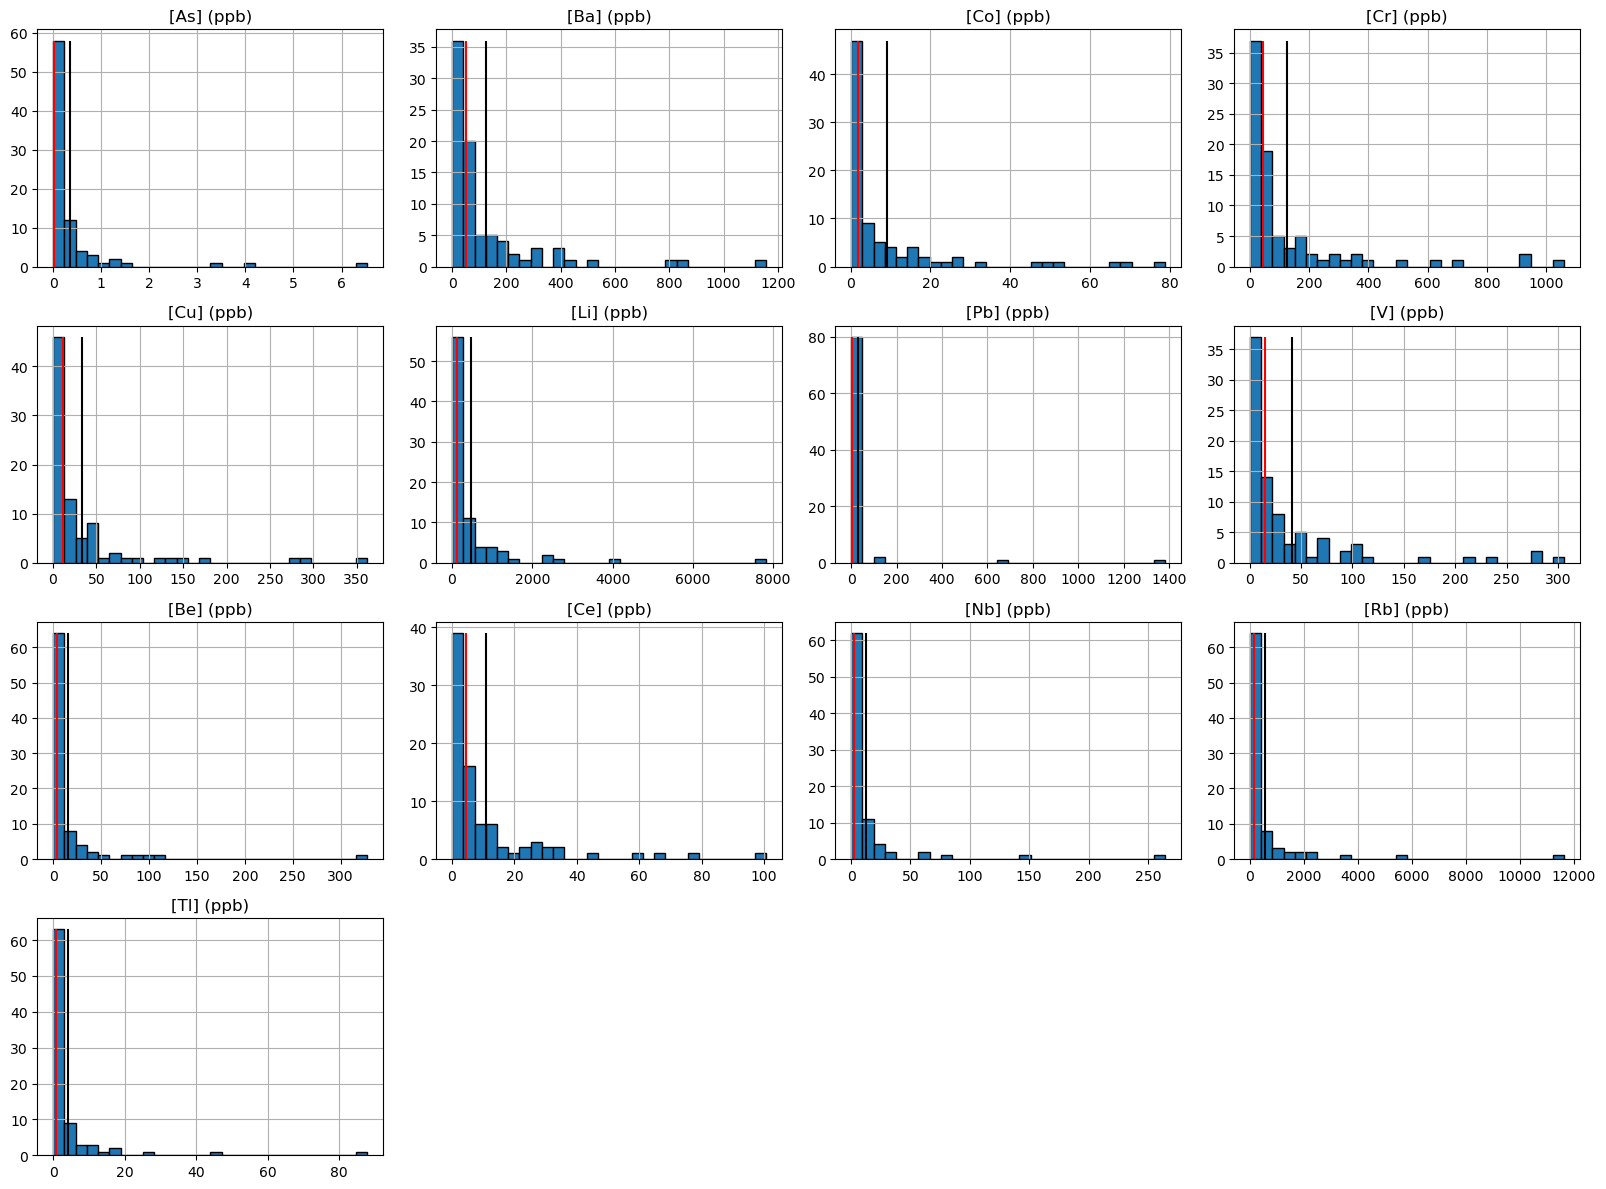

In [24]:
multiple_hist(df,ppb_cols)

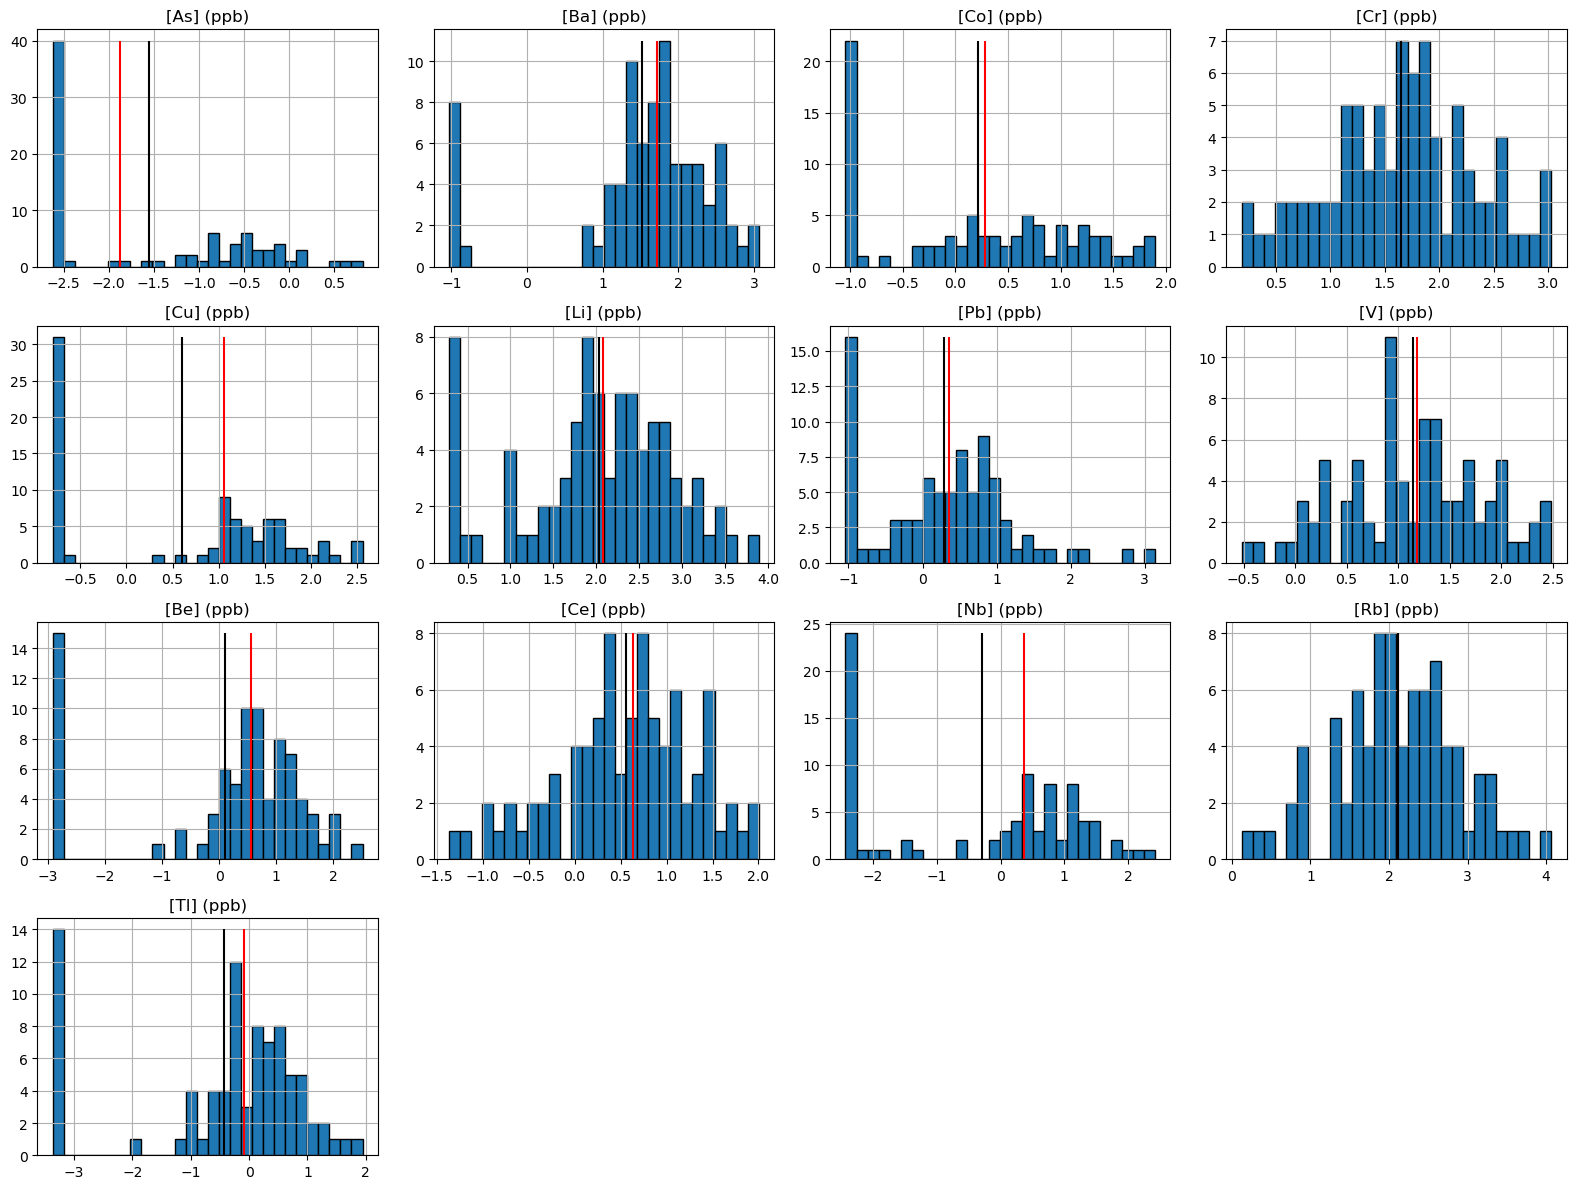

In [25]:
multiple_hist(df,ppb_cols,log=True)

In [26]:
info_cols

['Sample ID', 'Season', 'Dust sampler_ID', 'Transect', 'Change in mass (mg)']

In [27]:
df[df['[As] (ppb)']> df['[As] (ppb)'].quantile(0.85)].loc[:,info_cols+list(ppb_cols)]

,Sample ID,Season,Dust sampler_ID,Transect,Change in mass (mg),[As] (ppb),[Ba] (ppb),[Co] (ppb),[Cr] (ppb),[Cu] (ppb),[Li] (ppb),[Pb] (ppb),[V] (ppb),[Be] (ppb),[Ce] (ppb),[Nb] (ppb),[Rb] (ppb),[Tl] (ppb)
0,SA-1A-W24,Winter 2024,SA-1A,1,158.4,3.305565,413.387452,18.970530,193.851385,86.265748,341.341882,12.637742,108.354227,7.649300,35.840804,10.759476,376.978013,2.825006
1,SA-1B-W24,Winter 2024,SA-1B,1,45.9,0.675154,109.066547,5.826382,95.741806,47.572185,233.428202,5.946764,32.233836,5.507681,8.916619,4.696257,236.361473,1.559394
3,SA-1D-W24,Winter 2024,SA-1D,1,27.3,0.566408,53.388902,1.850280,21.624400,16.733698,67.193254,3.170979,12.251061,1.134764,3.761075,1.280460,60.391689,0.257287
4,SA-2A-W24,Winter 2024,SA-2A,2,261.5,0.880208,437.616048,66.785153,919.333001,277.148603,1356.550026,26.553747,236.413092,37.956021,46.704500,35.603081,1732.142402,11.938989
13,SA-5A-W24,Winter 2024,SA-5A,5,331.2,1.468275,510.312570,78.944227,1061.100666,291.980602,1623.460066,26.906778,274.430444,40.303499,57.859993,34.247945,1991.218768,14.024902
25,SA-REF-4-W24,Winter 2024,SA-REF-4,Ref_internal,357.0,1.385010,245.245772,21.442769,280.030996,122.781638,2600.138228,37.257794,93.731617,115.018324,24.974669,81.997659,3608.165919,26.906969
26,SA-REF-5-W24,Winter 2024,SA-REF-5,Ref_internal,1025.3,0.742959,804.741248,69.372029,942.983101,362.313822,7830.069826,123.882904,283.989662,327.910226,77.943745,264.721563,11644.083222,87.958907
27,SA-1A-S25,Spring-Summer 2025,SA-1A,1,707.1,6.537778,1157.776394,52.658473,383.408082,149.837324,592.869050,666.217176,306.201848,11.573121,100.782768,18.486121,447.461889,3.241564
28,SA-1B-S25,Spring-Summer 2025,SA-1B,1,132.3,0.951515,160.612859,9.783448,98.454534,21.312056,229.965705,0.203645,50.927953,5.719708,13.705820,3.200057,197.582098,1.289174
30,SA-1D-S25,Spring-Summer 2025,SA-1D,1,146.6,4.077925,225.098107,15.904732,76.979913,34.569542,74.735633,0.678529,73.844069,2.124867,24.484782,2.675478,109.893751,0.573882


In [28]:
# Assuming 'df' is your DataFrame and 'target_cols' is your list of column names
all_top_indexes = []

for col in cols_interest:
    # Gets the top 5 values and their indexes from the current column
    top_5_series = df[col].nlargest(5)
    
    # Add the indexes to the master list
    all_top_indexes.extend(top_5_series.index.tolist())
all_top_indexes = pd.Series(all_top_indexes)

In [29]:
all_top_indexes.value_counts()

26    29
54    28
13    22
27    18
4     16
25    13
83     8
38     6
5      5
0      3
20     2
8      2
24     2
30     1
6      1
55     1
31     1
36     1
33     1
11     1
82     1
16     1
2      1
39     1
Name: count, dtype: int64

In [ ]:
all_top_indexes.value_counts().sort_values(ascending=False)

26    29
54    28
13    22
27    18
4     16
25    13
83     8
38     6
5      5
0      3
20     2
8      2
24     2
30     1
6      1
55     1
31     1
36     1
33     1
11     1
82     1
16     1
2      1
39     1
Name: count, dtype: int64

## Samples repeatedly appearing on the highest concentrations

In [30]:
highest_indexes = all_top_indexes.value_counts().sort_values(ascending=False).index
df.loc[highest_indexes,'Sample ID']

26    SA-REF-5-W24
54    SA-REF-5-S25
13       SA-5A-W24
27       SA-1A-S25
4        SA-2A-W24
25    SA-REF-4-W24
83    SA-REF-5-F25
38       SA-4A-S25
5        SA-2B-W24
0        SA-1A-W24
20       SA-6C-W24
8        SA-3A-W24
24    SA-REF-3-W24
30       SA-1D-S25
6        SA-2C-W24
55       SA-1A-F25
31       SA-2A-S25
36       SA-3B-S25
33       SA-2C-S25
11       SA-4A-W24
82    SA-REF-4-F25
16       SA-5E-W24
2        SA-1C-W24
39       SA-4B-S25
Name: Sample ID, dtype: object

# Boxplots

In [ ]:
df.head()

,Sample ID,Season,Dust sampler_ID,Transect,LatDecimal,LonDecimal,LatDMS,LonDMS,distance,check ID,...,[Sr] (ppm),[Ti] (ppm),[V] (ppb),[Zn] (ppm),[Zr] (ppm),[Be] (ppb),[Ce] (ppb),[Nb] (ppb),[Rb] (ppb),[Tl] (ppb)
0,SA-1A-W24,Winter 2024,SA-1A,1,48.420833,-77.835833,48°25′15″,-77°50′9″,0,SA-1A-W24,...,0.357517,4.323584,108.354227,0.118321,0.095204,7.649300,35.840804,10.759476,376.978013,2.825006
1,SA-1B-W24,Winter 2024,SA-1B,1,48.421944,-77.836389,48°25′19″,-77°50′11″,50,SA-1B-W24,...,0.080506,1.183437,32.233836,0.038679,0.021186,5.507681,8.916619,4.696257,236.361473,1.559394
2,SA-1C-W24,Winter 2024,SA-1C,1,48.422500,-77.837222,48°25′21″,-77°50′14″,200,SA-1C-W24,...,0.045525,0.654697,17.023785,0.018585,0.010218,3.740547,5.071719,2.831953,148.790741,1.129325
3,SA-1D-W24,Winter 2024,SA-1D,1,48.423889,-77.840556,48°25′26″,-77°50′26″,500,SA-1D-W24,...,0.034486,0.471172,12.251061,0.017722,0.011153,1.134764,3.761075,1.280460,60.391689,0.257287
4,SA-2A-W24,Winter 2024,SA-2A,2,48.410556,-77.803056,48°24′38″,-77°48′11″,0,SA-2A-W24,...,0.368426,8.172379,236.413092,0.292857,0.075055,37.956021,46.704500,35.603081,1732.142402,11.938989


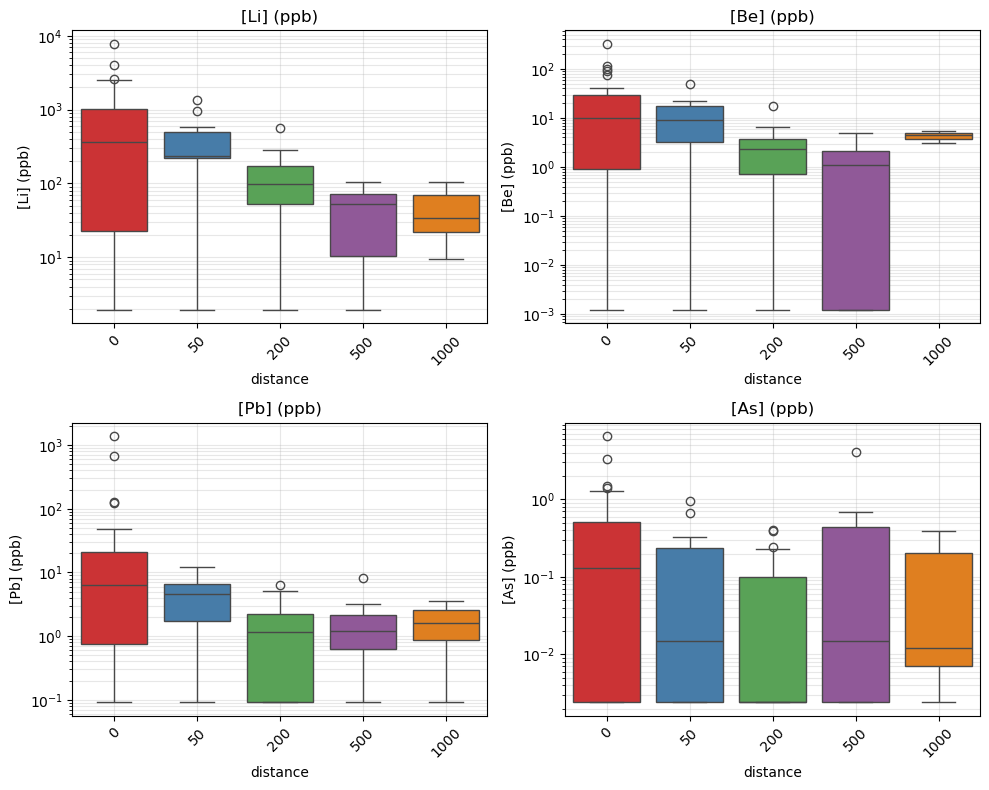

In [42]:


# add log to these boxplots
# def multi_boxplot(dataframe,colunns_plot,variable_interest,n_cols = 4,show_points=False):

# 	color_palette = 'Set1' 
	
# 	n_rows = int(np.ceil(len(colunns_plot) / n_cols))

# 	fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 3*n_rows))
# 	axes = axes.flatten()  # make iterable

# 	for i, column in enumerate(colunns_plot):

# 		# freq, bin_edges = np.histogram(array, bins=n_bins)

# 		sns.boxplot(x=variable_interest, y=column, data=dataframe, ax=axes[i], hue=variable_interest, palette=color_palette, legend=False)
# 		if show_points:
# 			sns.stripplot(x=variable_interest, y=column, data=dataframe, color="0.3", jitter=True, ax=axes[i])

# 		axes[i].set_title(f"{column}")
# 		axes[i].grid(True)

# 	# Remove unused subplots if n_sets < n_rows*n_cols
# 	for j in range(i+1, len(axes)):
# 		fig.delaxes(axes[j])

# 	plt.tight_layout()
# 	plt.show()

def multi_boxplot(
    dataframe,
    colunns_plot,
    variable_interest,
    n_cols=4,
    show_points=False,
    log_scale=True,
    log_floor=1E-6
):
    color_palette = 'Set1'

    n_rows = int(np.ceil(len(colunns_plot) / n_cols))

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(5*n_cols, 4*n_rows)
    )

    axes = np.atleast_1d(axes).flatten()

    for i, column in enumerate(colunns_plot):

        # Copy data to avoid modifying the original dataframe
        plot_data = dataframe[[variable_interest, column]].copy()

        if log_scale:
            # Remove invalid values
            plot_data[column] = pd.to_numeric(
                plot_data[column], errors='coerce'
            )

            plot_data = plot_data[
                np.isfinite(plot_data[column])
            ]

            # Handle zero and negative values
            if log_floor is not None:
                plot_data[column] = plot_data[column].clip(
                    lower=log_floor
                )
            else:
                plot_data = plot_data[plot_data[column] > 0]

        sns.boxplot(
            x=variable_interest,
            y=column,
            data=plot_data,
            ax=axes[i],
            hue=variable_interest,
            palette=color_palette,
            legend=False
        )

        if show_points:
            sns.stripplot(
                x=variable_interest,
                y=column,
                data=plot_data,
                color="0.3",
                jitter=True,
                ax=axes[i]
            )

        if log_scale:
            axes[i].set_yscale('log')

        axes[i].set_title(column)
        axes[i].grid(True, which='both', alpha=0.3)
        axes[i].tick_params(axis="x", labelrotation=45)

    # Remove unused subplots
    for j in range(len(colunns_plot), len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

multi_boxplot(dataframe=df,colunns_plot=['[Li] (ppb)', '[Be] (ppb)',  '[Pb] (ppb)','[As] (ppb)'],variable_interest='distance', n_cols=2,log_scale=True)

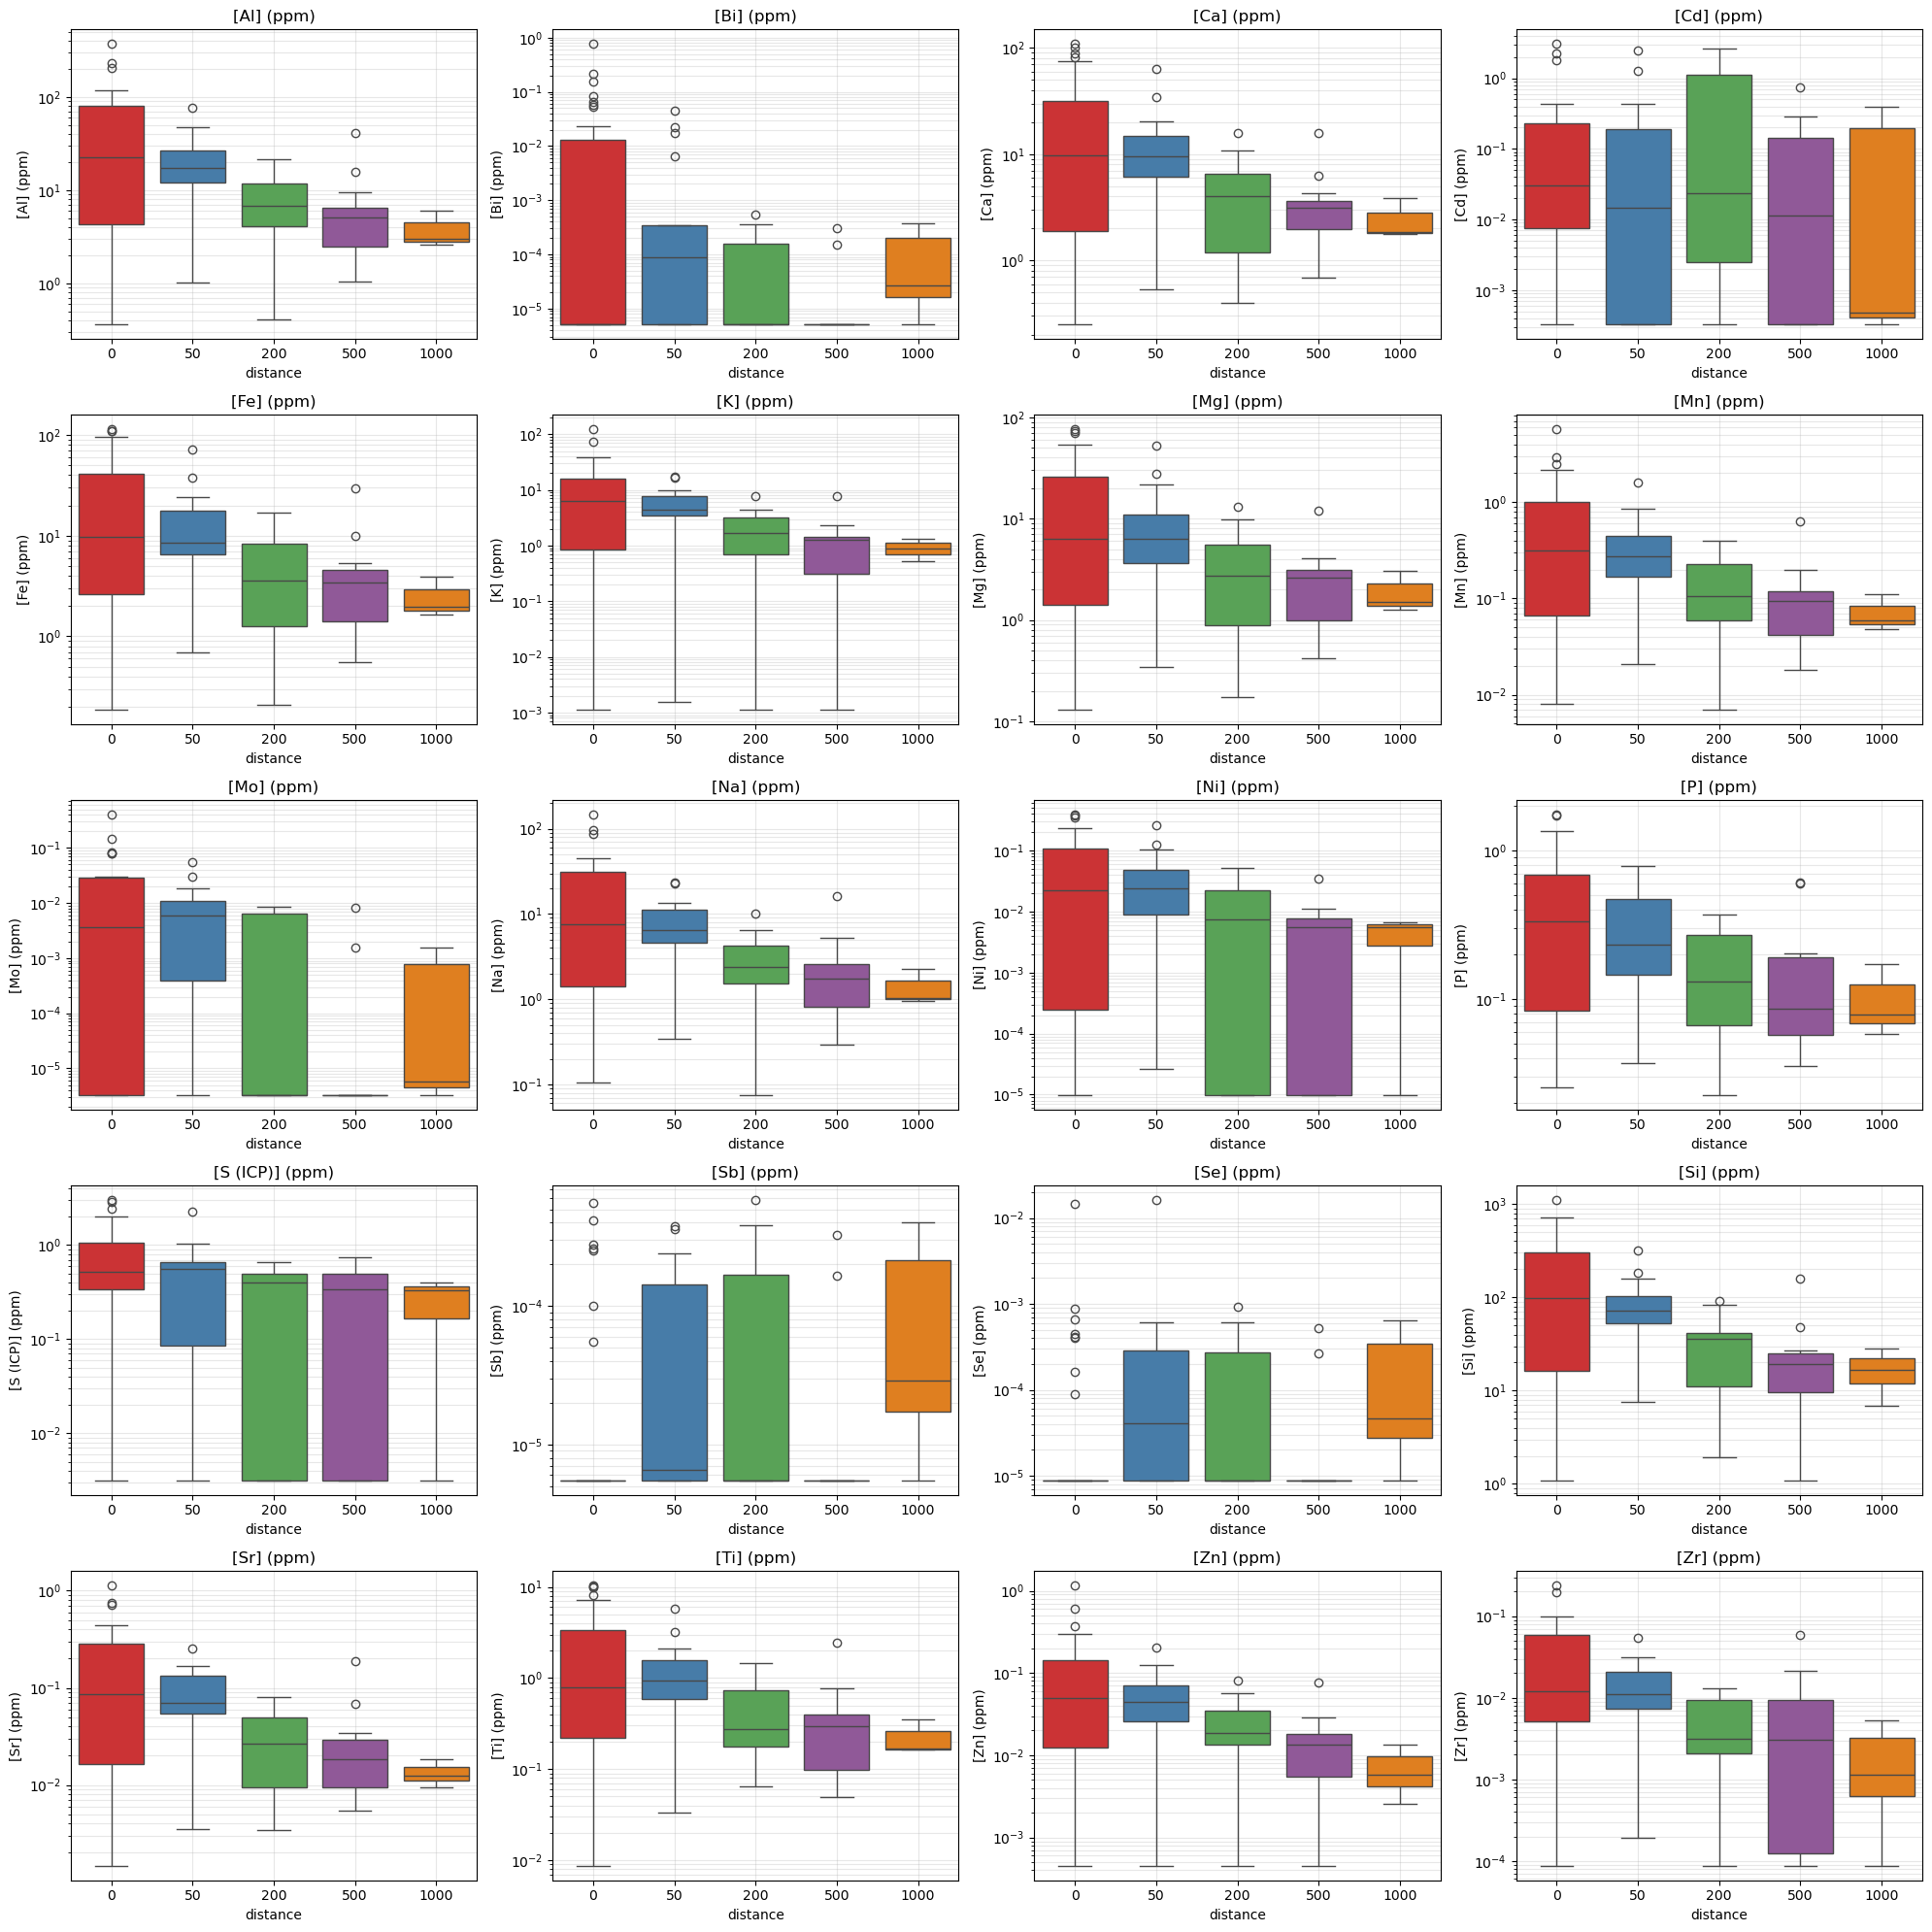

In [39]:
multi_boxplot(dataframe=df,colunns_plot=ppm_cols,variable_interest='distance',log_scale=True)

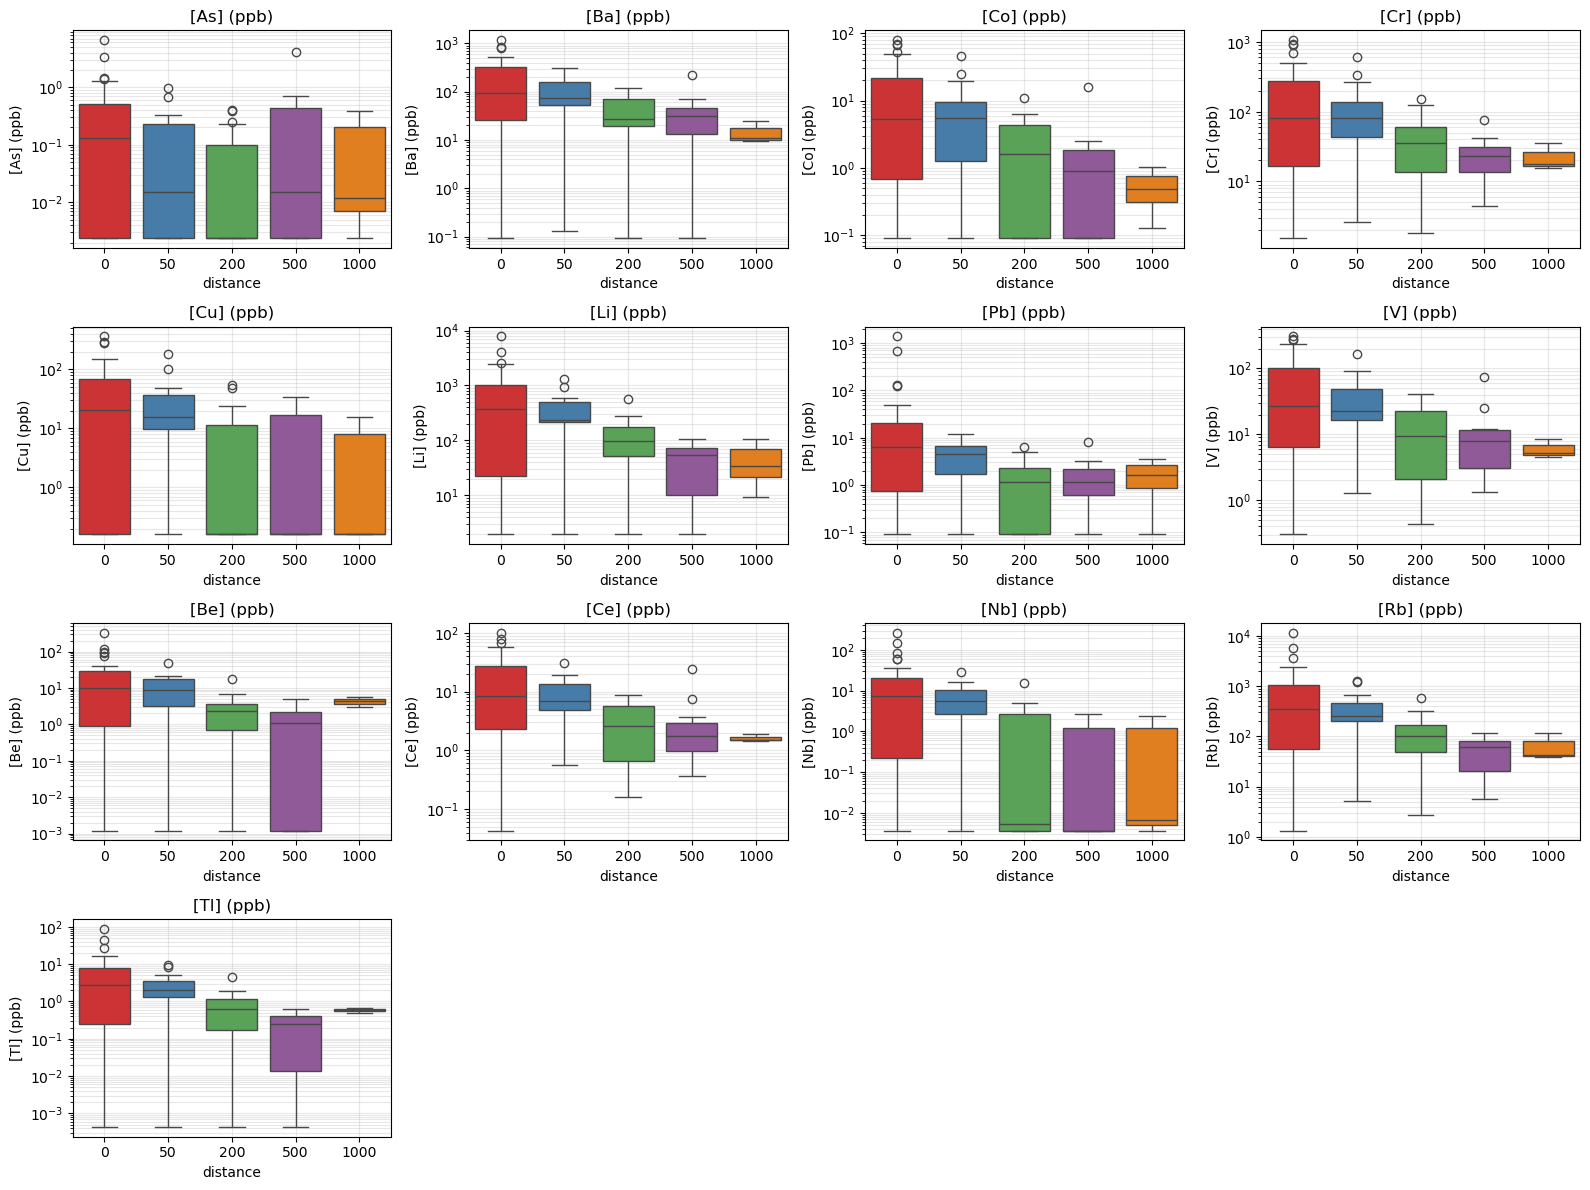

In [34]:
multi_boxplot(dataframe=df,colunns_plot=ppb_cols,variable_interest='distance',log_scale=True)

In [34]:
ppb_cols, ppm_cols

(Index(['[As] (ppb)', '[Ba] (ppb)', '[Co] (ppb)', '[Cr] (ppb)', '[Cu] (ppb)',
        '[Li] (ppb)', '[Pb] (ppb)', '[V] (ppb)', '[Be] (ppb)', '[Ce] (ppb)',
        '[Nb] (ppb)', '[Rb] (ppb)', '[Tl] (ppb)'],
       dtype='object'),
 Index(['[Al] (ppm)', '[Bi] (ppm)', '[Ca] (ppm)', '[Cd] (ppm)', '[Fe] (ppm)',
        '[K] (ppm)', '[Mg] (ppm)', '[Mn] (ppm)', '[Mo] (ppm)', '[Na] (ppm)',
        '[Ni] (ppm)', '[P] (ppm)', '[S (ICP)] (ppm)', '[Sb] (ppm)',
        '[Se] (ppm)', '[Si] (ppm)', '[Sr] (ppm)', '[Ti] (ppm)', '[Zn] (ppm)',
        '[Zr] (ppm)'],
       dtype='object'))

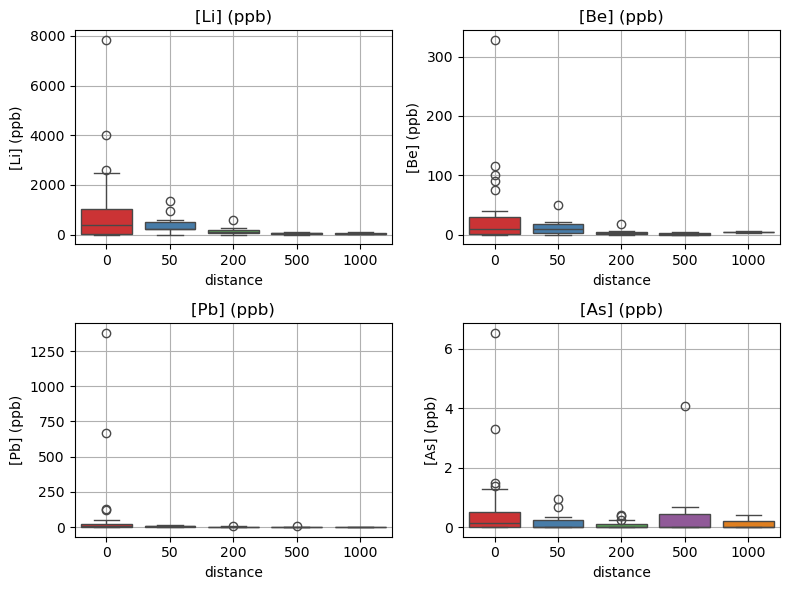

In [35]:
multi_boxplot(dataframe=df,colunns_plot=['[Li] (ppb)', '[Be] (ppb)',  '[Pb] (ppb)','[As] (ppb)'],variable_interest='distance', n_cols=2)

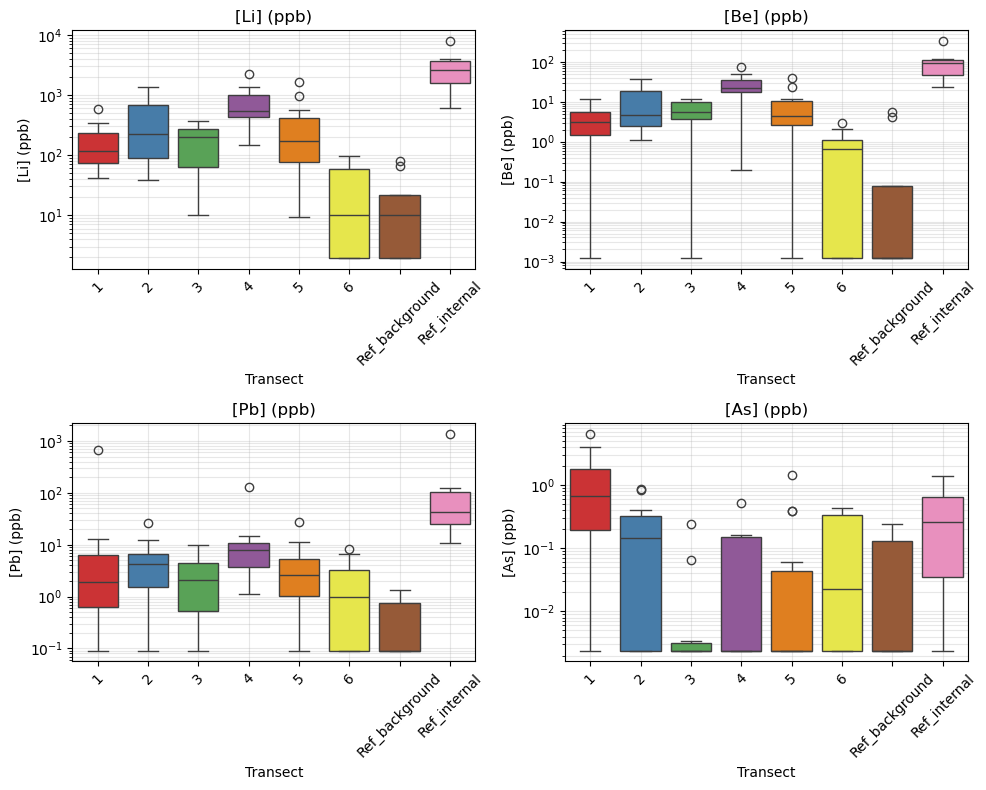

In [43]:
multi_boxplot(dataframe=df,colunns_plot=['[Li] (ppb)', '[Be] (ppb)',  '[Pb] (ppb)','[As] (ppb)'],variable_interest='Transect', n_cols=2)

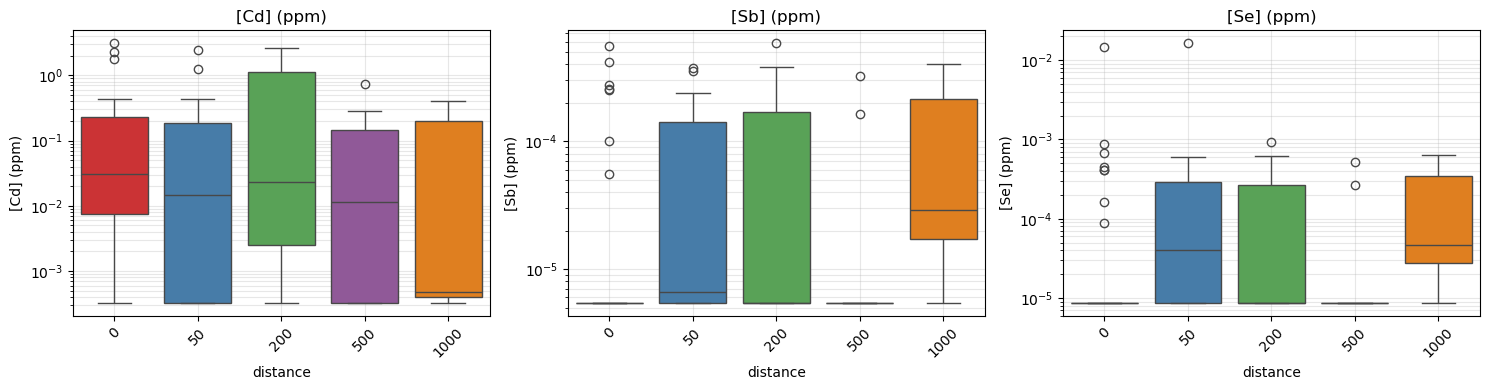

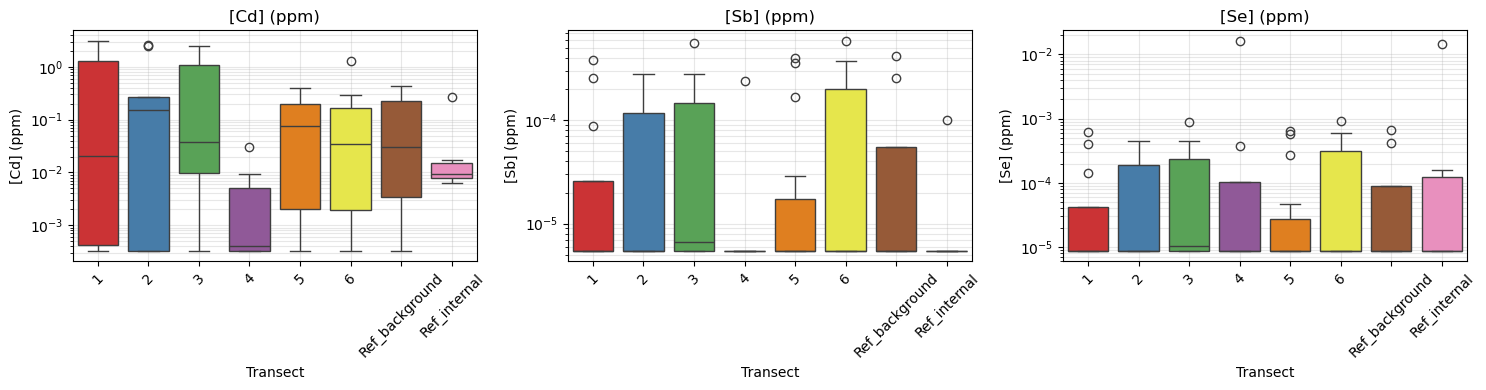

In [44]:
multi_boxplot(dataframe=df,colunns_plot=['[Cd] (ppm)', '[Sb] (ppm)',  '[Se] (ppm)'],variable_interest='distance', n_cols=3)
multi_boxplot(dataframe=df,colunns_plot=['[Cd] (ppm)', '[Sb] (ppm)',  '[Se] (ppm)'],variable_interest='Transect', n_cols=3)

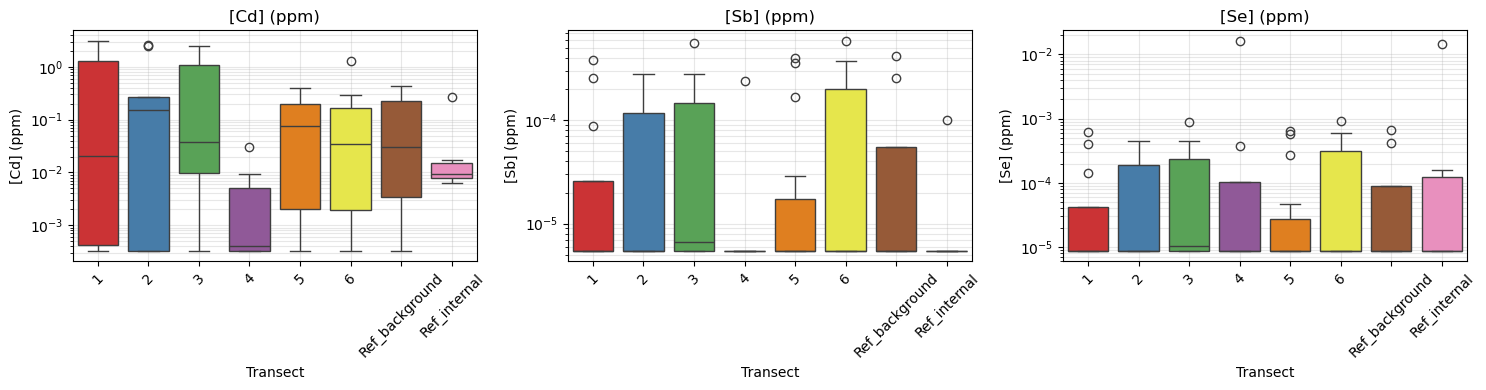

In [45]:
multi_boxplot(dataframe=df,colunns_plot=['[Cd] (ppm)', '[Sb] (ppm)',  '[Se] (ppm)'],variable_interest='Transect', n_cols=3)

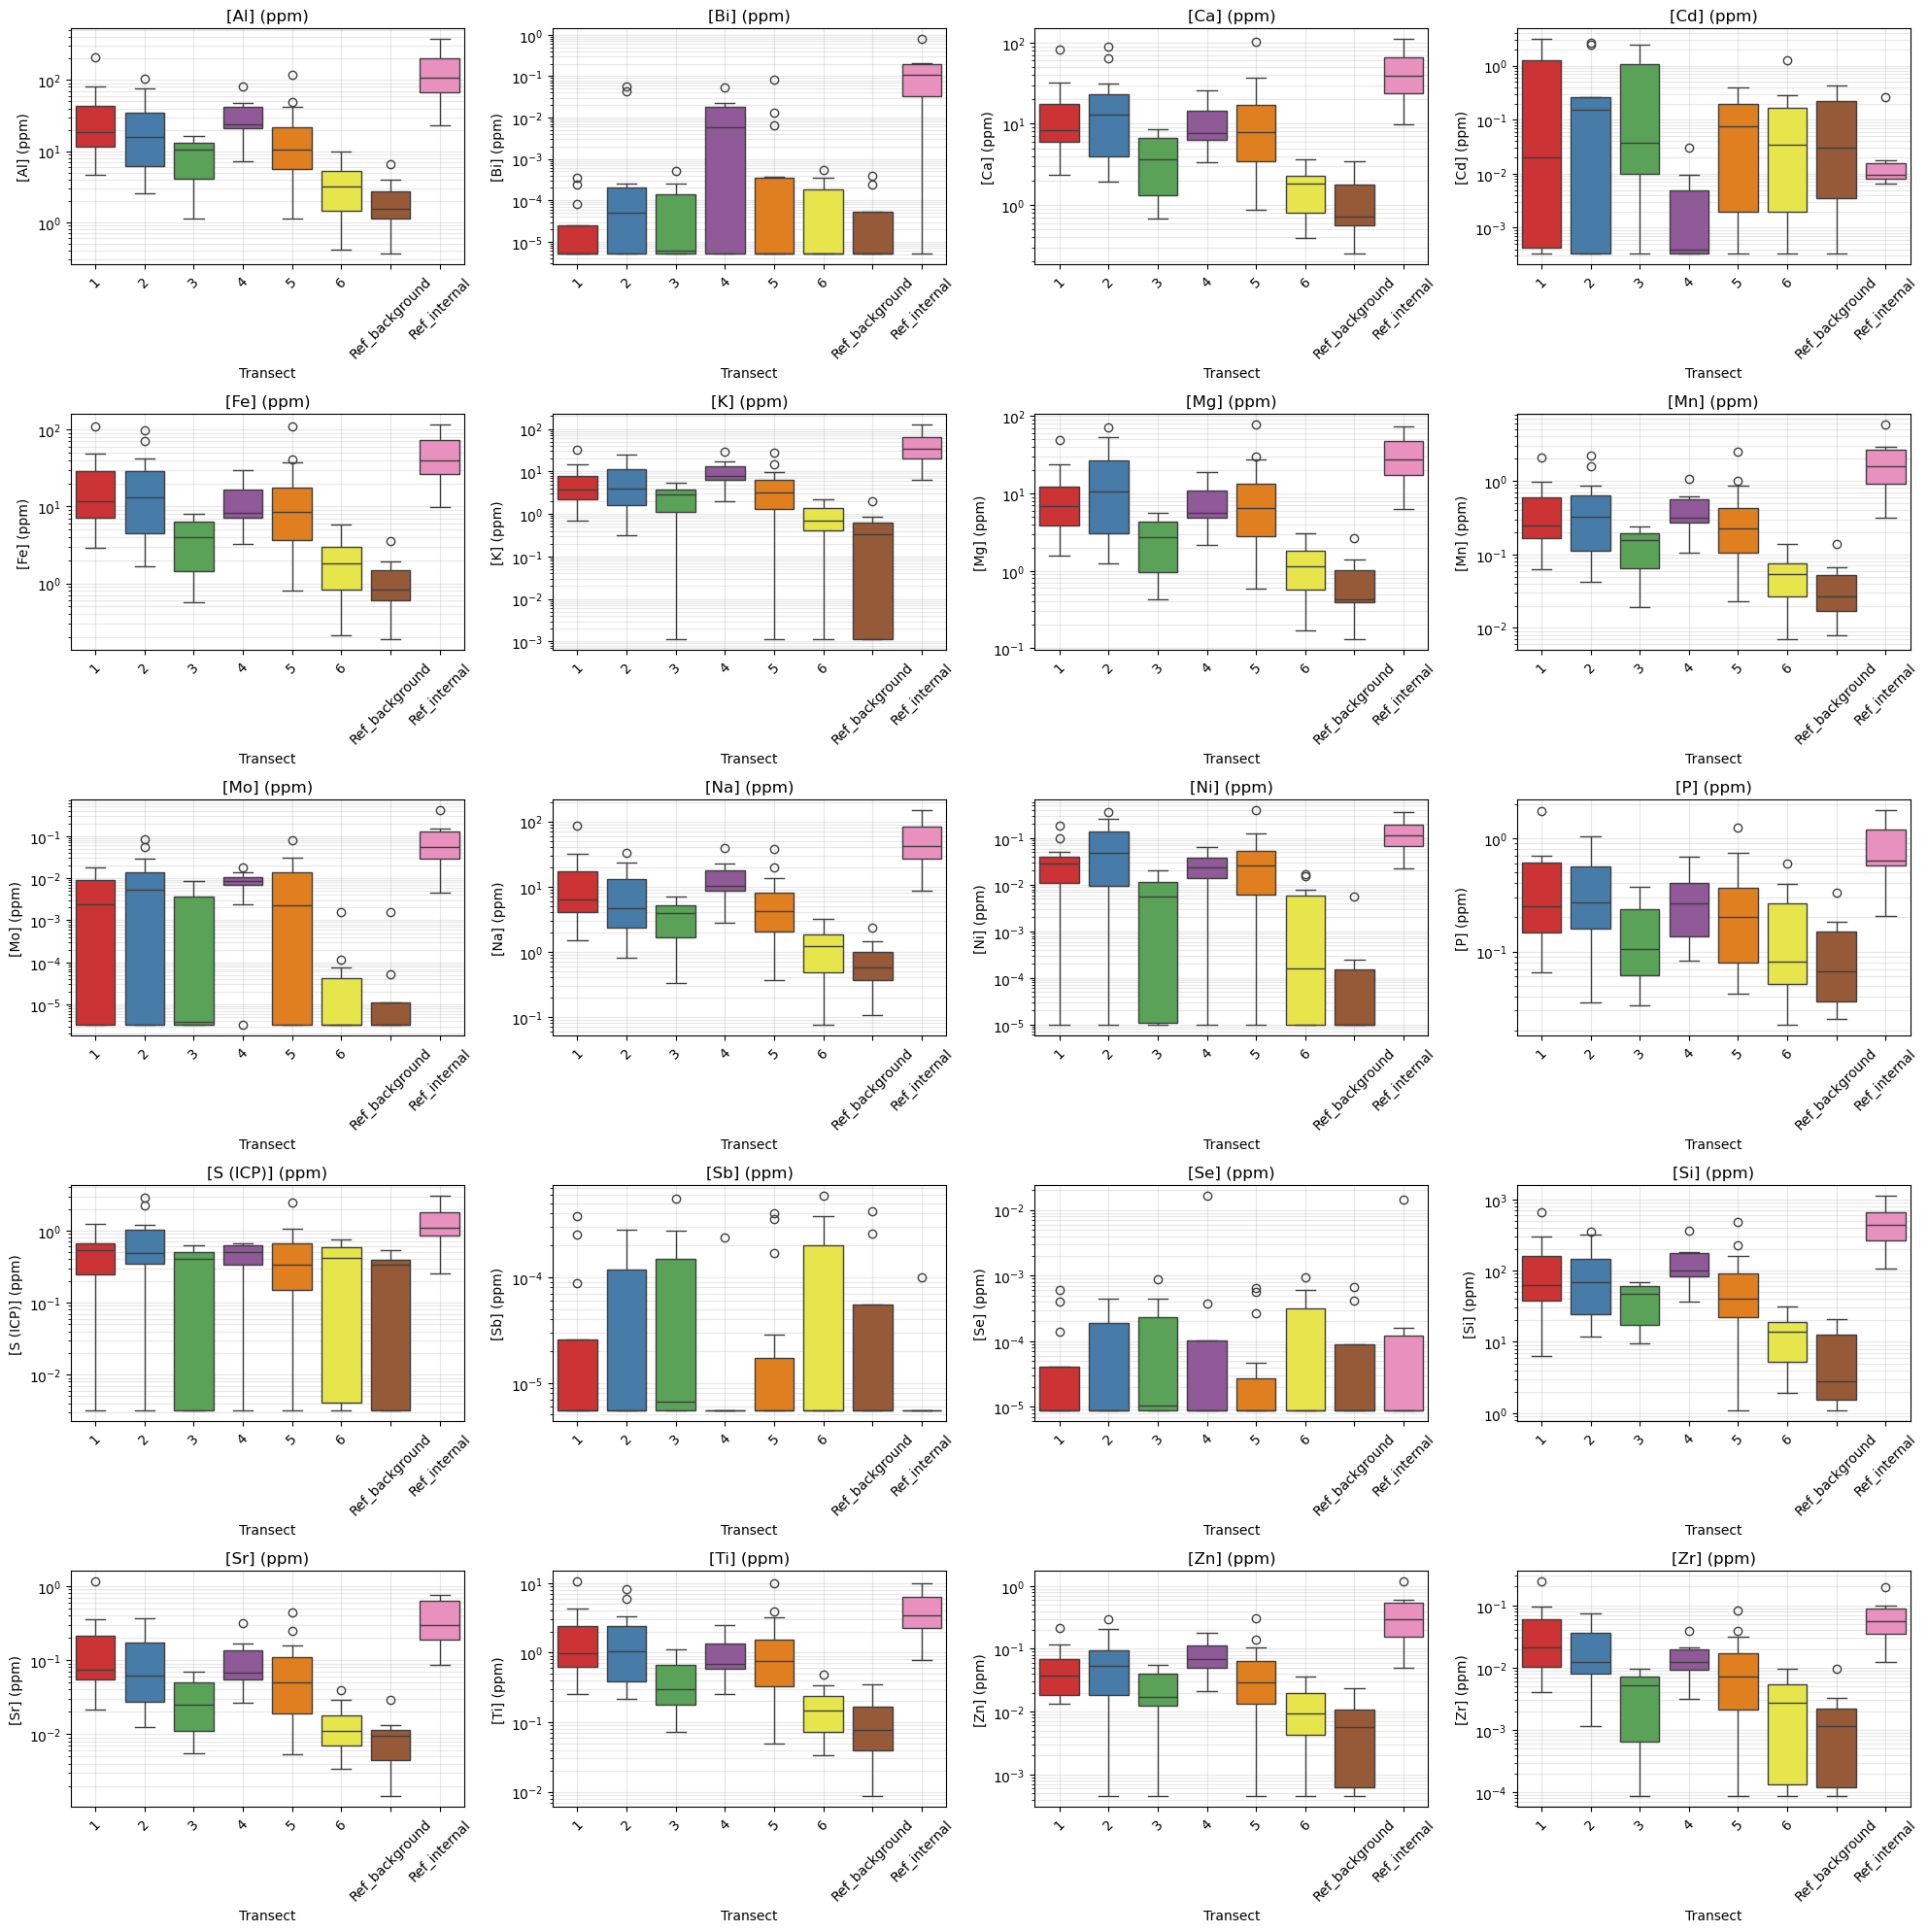

In [46]:
multi_boxplot(dataframe=df,colunns_plot=ppm_cols,variable_interest='Transect')

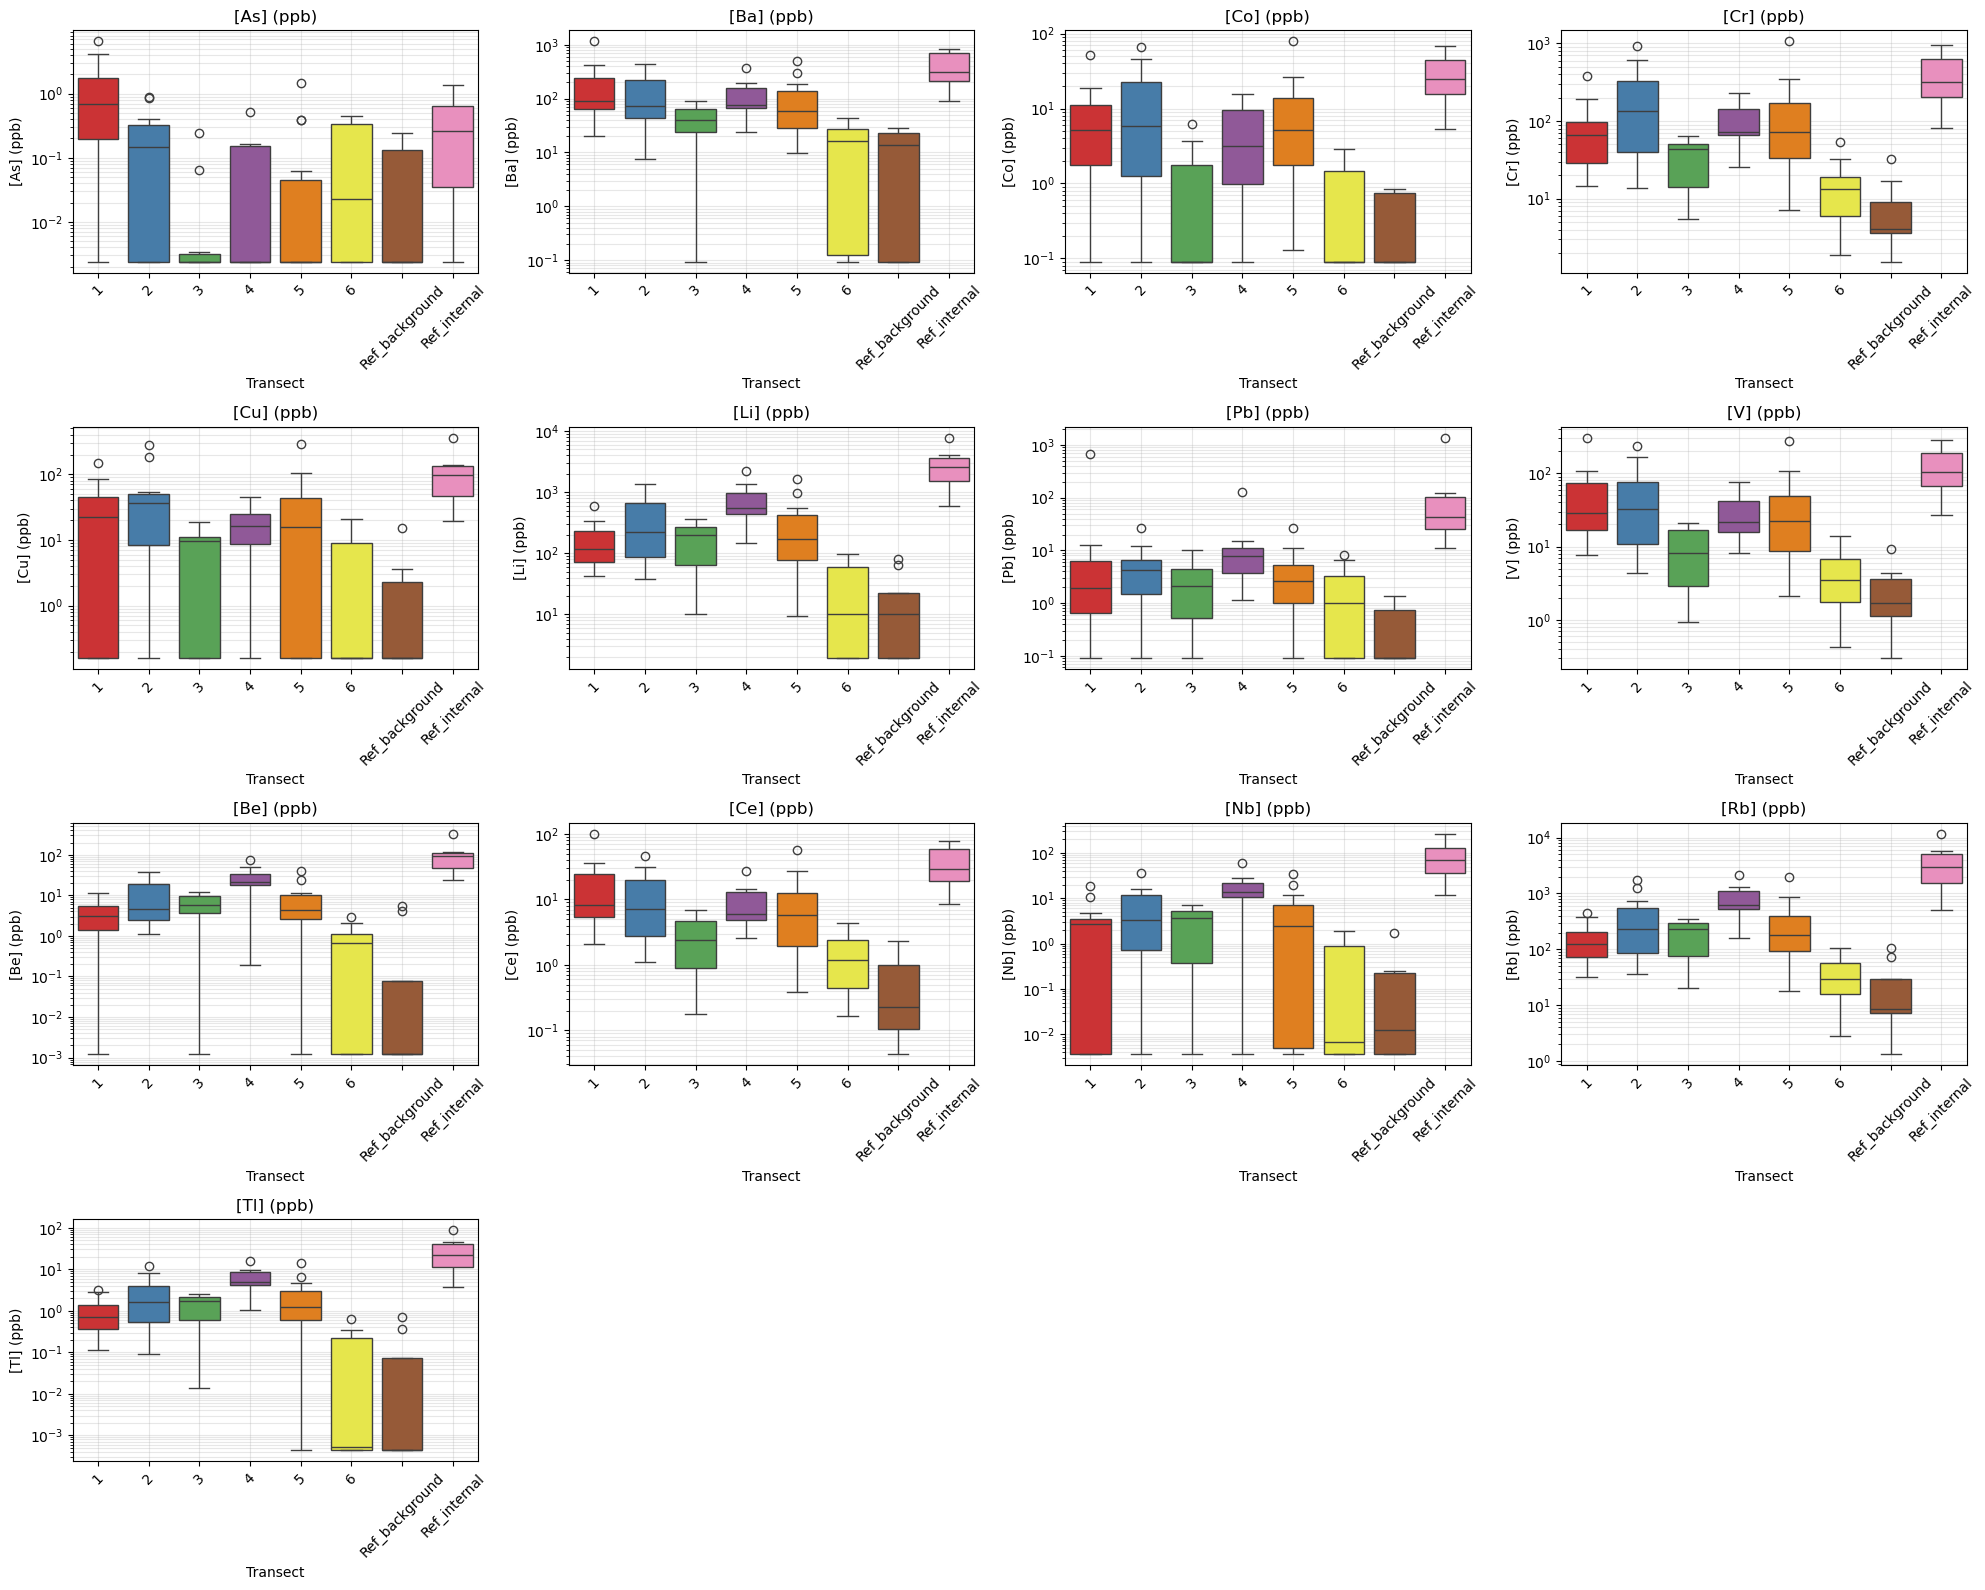

In [47]:
multi_boxplot(dataframe=df,colunns_plot=ppb_cols,variable_interest='Transect')

# Be measurements

Beryllium is a confirmed human carcinogen. The critical effects of exposure to beryllium are lung cancer and berylliosis. The present ACGIH TLV (the legal exposure limit) for beryllium is only 0.05 micrograms of the element per cubic meter of inhaled air and is under review. Therefore, exposure to dust, fumes and substances containing beryllium should be avoided or strictly monitored and controlled. 
https://www.canada.ca/en/employment-social-development/services/health-safety/prevention/beryllium.html

Assuming the Beryllium ($\text{Be}$) mass is converted into an equivalent volume concentration: 
	Ideal Gas Law ($PV=nRT$)
	Atomic Weight of Beryllium ($\mathbf{Be}$) ($9.012 \text{ g/mol}$)
	P = 1 atm
	T = range -40 to 30

mass concentration ($C_{\mu \text{g/m}^3}$) to volume concentration ($\text{ppb}$)

$$ \text{ppb} = \frac{C_{\mu \text{g/m}^3} \times V_m}{MW} $$

where $V_m$ is the molar volume in $\text{L/mol}$ (calculated as $V_m = \frac{RT}{P}$)

$$R = \mathbf{0.082057 \frac{\text{L} \cdot \text{atm}}{\text{mol} \cdot \text{K}}}$$

number of moles ($n$) of Beryllium present in the $0.5 \ \mu \text{g}$  (in $1 \text{ m}^3$ air)

In [41]:
mass = 0.05 * 1E-6 # microgram -> 0.5*1E-6
molecular_weight = 9.012 # g/mol
n = mass / molecular_weight # mass/ mol_weight
n

5.548158011540168e-09

In [42]:
gas_const = 0.082057
pressure = 1 #atm
t = np.linspace(-40,30,7)
t += t+273.15
t 

array([193.15      , 216.48333333, 239.81666667, 263.15      ,
       286.48333333, 309.81666667, 333.15      ])

In [43]:
v = (n * gas_const * t )/pressure
v

array([8.79344738e-08, 9.85573285e-08, 1.09180183e-07, 1.19803038e-07,
       1.30425893e-07, 1.41048747e-07, 1.51671602e-07])

$$\text{ppb} = \frac{\text{Volume of Beryllium } (V)}{\text{Volume of Air}} \times 10^9$$

$\frac{V}{1000 \text{ L}}$ calculates the volume ratio (since $1 \text{ m}^3 = 1000 \text{ L}$).

$\times 10^9$ converts the volume ratio to parts per billion.

In [44]:
ppb = (v / 1000) * 1E9
ppb

array([0.08793447, 0.09855733, 0.10918018, 0.11980304, 0.13042589,
       0.14104875, 0.1516716 ])

In [45]:
df['[Be] (ppb)'].describe()

count     84.000000
mean      15.463159
std       40.652013
min        0.001218
25%        0.899182
50%        3.602731
75%       11.500758
max      327.910226
Name: [Be] (ppb), dtype: float64

# Cluster and PCA

In [51]:
norm_data = (df[cols_interest] - df[cols_interest].min()) / (df[cols_interest].max() - df[cols_interest].min())

from sklearn.cluster import KMeans

def cluster_data(data, n_clusters=6, random_state=42):
    """
    Fit KMeans and return cluster labels.
    
    data : dataframe or array with features
    """
    model = KMeans(n_clusters=n_clusters, random_state=random_state)
    labels = model.fit_predict(data)
    return labels, model
df['cluster'], kmeans_model = cluster_data(norm_data.loc[:,cols_interest], n_clusters=5)
df['cluster']

c:\Users\bruno\anaconda3\envs\experimental\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] O sistema não pode encontrar o arquivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\bruno\anaconda3\envs\experimental\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\bruno\anaconda3\envs\experimental\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\bruno\anaconda3\envs\experimental\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\bruno\anaconda3\envs\ex

0     0
1     1
2     1
3     1
4     2
     ..
79    1
80    1
81    1
82    1
83    0
Name: cluster, Length: 84, dtype: int32

In [52]:
from sklearn.decomposition import PCA
def get_pca(norm_data,n_components):
    

    # Fit the PCA model to the scaled data
    pca = PCA(n_components=n_components).fit(norm_data)


    # Transform the data to the principal component space
    components = pca.transform(norm_data)

    # Explained variance ratio
    per_var = np.round(pca.explained_variance_ratio_ * 100 , 1)

    # Create labels for the scree plot
    labels = ['PC' + str(x) for x in range(1,len(per_var) +1 )]

    # Principal components dataframe
    components = pd.DataFrame(components)

    loadings_df = pd.DataFrame(pca.components_ , columns=norm_data.columns, index=labels) 

    return pca,components, loadings_df
# pca,components, loadings_df = get_pca(norm_data=norm_df,n_components=7)


In [53]:
pca,components, loadings_df = get_pca(norm_data=norm_data,n_components=7)


In [54]:
loadings_df.columns = [col.split(' ')[0].split('[')[1].split(']')[0] for col in loadings_df.columns]
loadings_df

,Al,As,Ba,Bi,Ca,Cd,Co,Cr,Cu,Fe,...,Sr,Ti,V,Zn,Zr,Be,Ce,Nb,Rb,Tl
PC1,0.166648,0.080285,0.184704,0.097353,0.240280,0.019225,0.235243,0.220776,0.198188,0.257932,...,0.169858,0.250475,0.245989,0.138563,0.170235,0.109334,0.199276,0.123364,0.120845,0.120359
PC2,-0.078951,0.302233,0.114266,-0.217350,0.053020,0.534000,0.067556,-0.009815,0.001229,0.124043,...,0.117925,0.137379,0.130313,-0.170166,0.120746,-0.230320,0.119553,-0.231449,-0.228339,-0.231943
PC3,0.088344,-0.041189,-0.002849,0.143119,-0.064883,0.336140,-0.116285,-0.089273,0.007399,-0.077482,...,-0.010973,-0.074098,-0.084586,0.104988,0.020566,0.140474,-0.031196,0.147497,0.137527,0.140773
PC4,-0.142000,-0.222420,-0.165687,-0.078131,0.103377,-0.358604,0.191085,0.271106,0.175326,0.065715,...,-0.192321,0.036193,0.030904,-0.063233,-0.198176,-0.091914,-0.124946,-0.106276,-0.074185,-0.082328
PC5,-0.048705,-0.257970,-0.198398,0.101840,0.025040,0.651492,0.021646,0.120947,0.148900,-0.032542,...,-0.201475,-0.047491,-0.071086,0.057959,-0.149206,0.069828,-0.159786,0.040441,0.065768,0.061521
PC6,-0.031175,-0.229581,0.070751,-0.135258,0.003061,0.151935,0.028315,0.096383,-0.124267,-0.008210,...,0.048486,-0.016478,-0.008837,-0.027891,-0.144115,-0.110678,0.009527,-0.004991,-0.024017,-0.014674
PC7,-0.023245,-0.255178,-0.040839,-0.023770,0.038535,0.104053,0.028951,0.084296,0.051863,-0.014898,...,-0.036311,-0.017457,-0.009395,-0.008658,-0.099776,0.015473,-0.043934,0.003440,0.007798,0.007449


In [55]:
def plot_pca_loadings(loadings_df, pcs=[0, 1]):

	alpha = 0.9
	fontsize = 18

	fig, ax = plt.subplots(1, 1, figsize=(6, 6))

	# -----------------------------
	# Loadings arrows
	# -----------------------------
	for col in loadings_df.columns:
		ax.arrow(
			0, 0,
			loadings_df.loc[f'PC{pcs[0]+1}', col],
			loadings_df.loc[f'PC{pcs[1]+1}', col],
			color='gray', alpha=alpha
		)

		ax.text(
			loadings_df.loc[f'PC{pcs[0]+1}', col] * 1.05,
			loadings_df.loc[f'PC{pcs[1]+1}', col] * 1.05,
			s=col,
			fontsize=fontsize - 6,
			color='k'
		)

	ax.set_xlabel(f'PC{pcs[0] + 1}', fontsize=fontsize)
	ax.set_ylabel(f'PC{pcs[1] + 1}', fontsize=fontsize)
	plt.show()


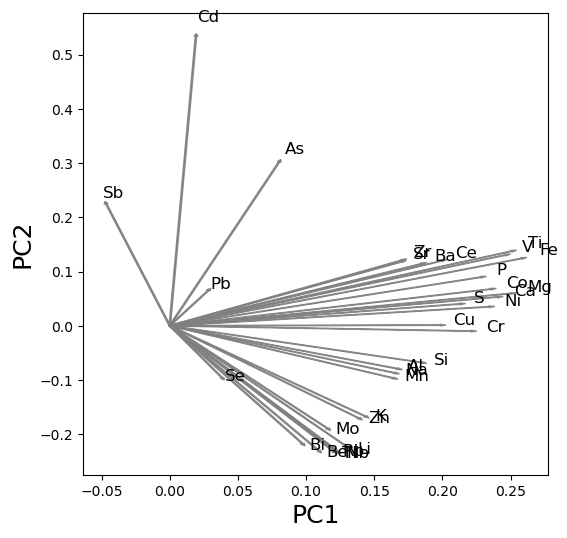

In [56]:
plot_pca_loadings(loadings_df, pcs=[0, 1])

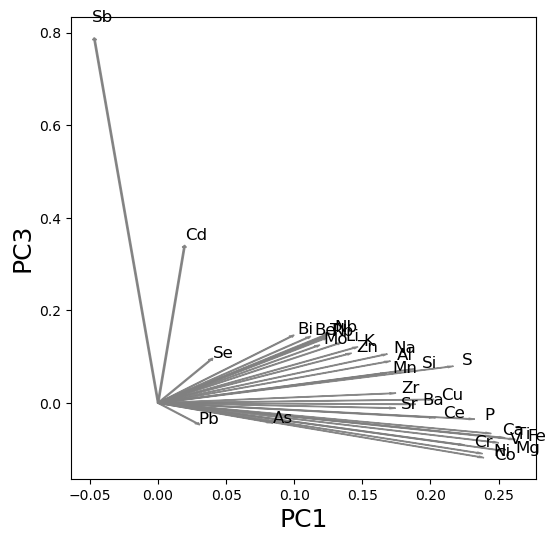

In [57]:
plot_pca_loadings(loadings_df, pcs=[0, 2])

In [89]:
def plot_pca_simple(components, loadings_df, dataframe, pcs=[0, 1],
                    color_map=None, cluster_col=None, annotate_col=None,log=True):

    alpha = 0.9
    fontsize = 18

    # Attach cluster labels + annotation column to components
    if cluster_col is not None:
        components[cluster_col] = dataframe[cluster_col]

    if annotate_col is not None:
        components[annotate_col] = dataframe[annotate_col]

    unique_clusters = sorted(components[cluster_col].unique())

    # Auto-color if not provided
    if color_map is None:
        palette = sns.color_palette("tab10", len(unique_clusters))
        color_map = dict(zip(unique_clusters, palette))

    # Legend handles
    legend_elements = [
        plt.Line2D([0], [0], marker='o', linestyle='',
                   markerfacecolor=color_map[c],
                   markersize=10, label=f'Cluster {c}')
        for c in unique_clusters
    ]

    fig, ax = plt.subplots(1, 1, figsize=(12, 9))

    # Scatter colors
    colors = [color_map[c] for c in components[cluster_col]]

    # PCA scatter
    ax.scatter(
        components.iloc[:, pcs[0]],
        components.iloc[:, pcs[1]],
        c=colors, s=40, alpha=alpha - 0.15
    )

    # -----------------------------
    #  FIXED ANNOTATION POSITIONING
    # -----------------------------
    if annotate_col is not None:
        for i, row in components.iterrows():

            x = row.iloc[pcs[0]]
            y = row.iloc[pcs[1]]


            ax.annotate(
                row[annotate_col],
                (x, y),
                xytext=(2  , 2  ),  # offset in points
                textcoords="offset points",
                ha="left",
                fontsize=10
            )
            # ax.annotate(
            #     row[annotate_col],
            #     (x, y),
            #     ha="left",
            #     fontsize=10
            # )

    # -----------------------------
    # Loadings arrows
    # -----------------------------
    # for col in loadings_df.columns:
    #     ax.arrow(
    #         0, 0,
    #         loadings_df.loc[f'PC{pcs[0]+1}', col],
    #         loadings_df.loc[f'PC{pcs[1]+1}', col],
    #         color='gray', alpha=alpha
    #     )

    #     ax.text(
    #         loadings_df.loc[f'PC{pcs[0]+1}', col] * 1.05,
    #         loadings_df.loc[f'PC{pcs[1]+1}', col] * 1.05,
    #         s=col,
    #         fontsize=fontsize - 6,
    #         color='k'
    #     )

    ax.set_xlabel(f'PC{pcs[0] + 1}', fontsize=fontsize)
    ax.set_ylabel(f'PC{pcs[1] + 1}', fontsize=fontsize)
    if log:
        ax.set_xscale("symlog", linthresh=1)
        ax.set_yscale("symlog", linthresh=1)

    ax.legend(
        handles=legend_elements,
        title="Cluster",
        bbox_to_anchor=(1.05, 1),
        loc='upper left'
    )



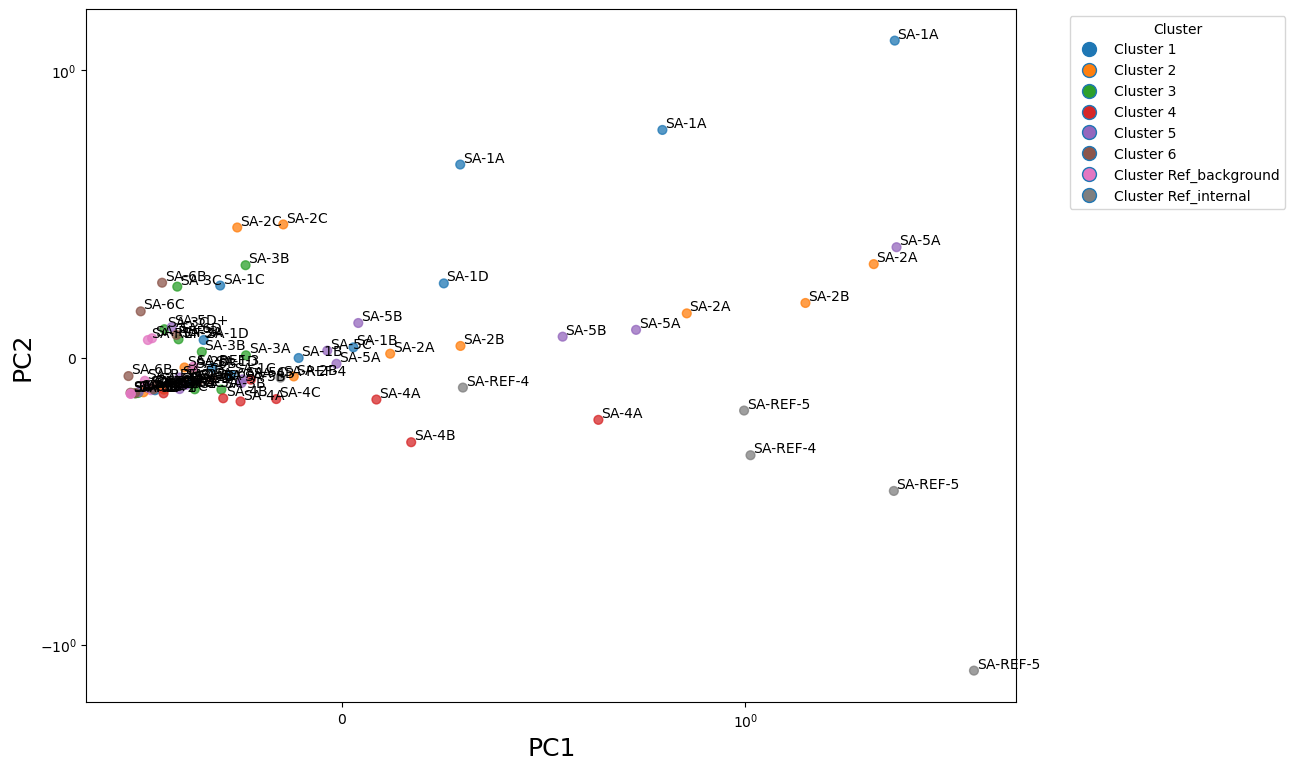

In [90]:
 

plot_pca_simple(components, loadings_df, df, pcs=[0, 1],
                    color_map=None, cluster_col='Transect', annotate_col='Dust sampler_ID')

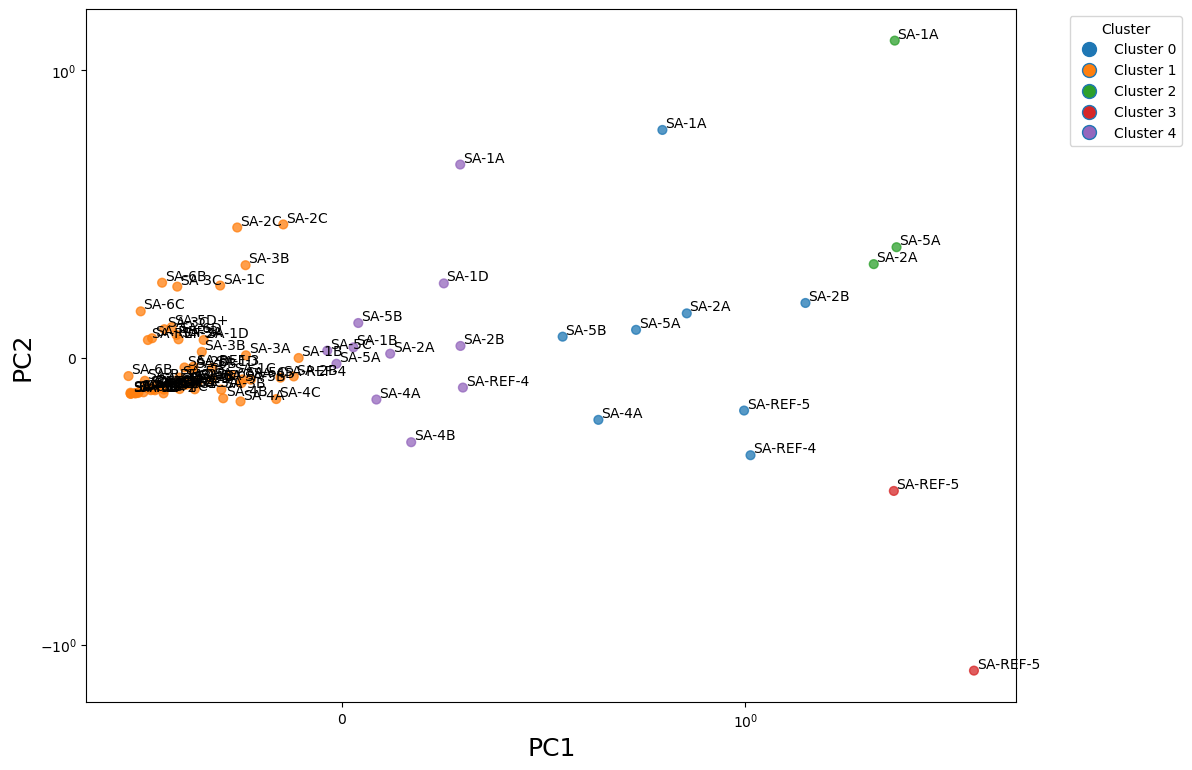

In [91]:

plot_pca_simple(components, loadings_df, df, pcs=[0, 1],
                    color_map=None, cluster_col='cluster', annotate_col='Dust sampler_ID')

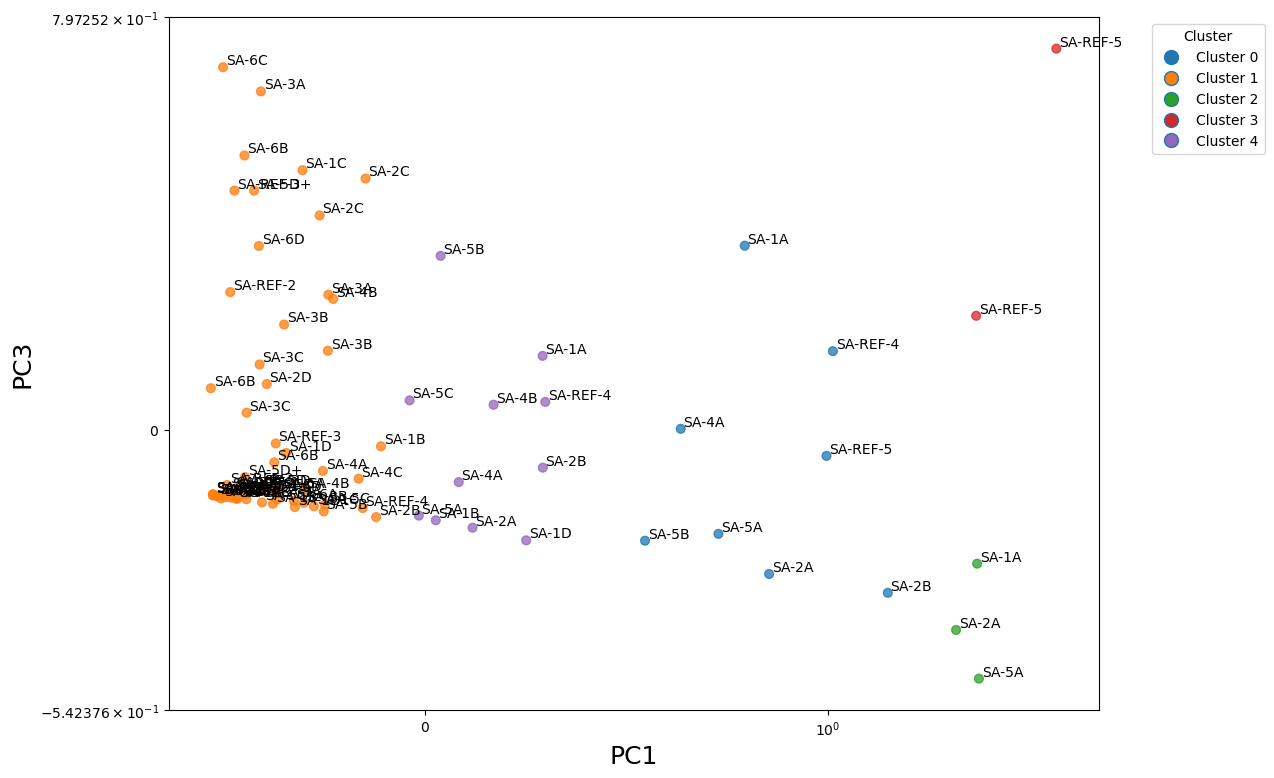

In [92]:

plot_pca_simple(components, loadings_df, df, pcs=[0, 2],
                    color_map=None, cluster_col='cluster', annotate_col='Dust sampler_ID')

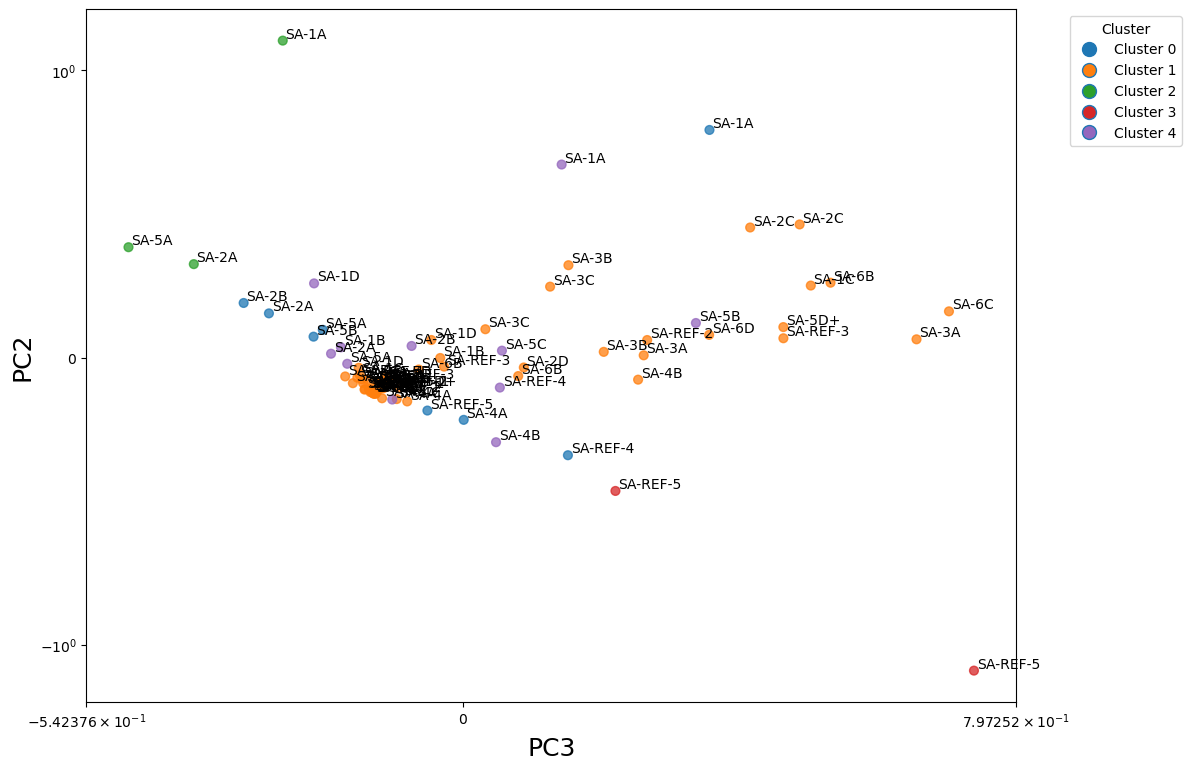

In [93]:

plot_pca_simple(components, loadings_df, df, pcs=[2, 1],
                    color_map=None, cluster_col='cluster', annotate_col='Dust sampler_ID')

In [68]:

def plot_ordered_loadings(loadings_df, pc=1, absolute=True, figsize=(8,5)):
    """
    Make a barplot of ordered PCA loadings for PCn.
    
    loadings_df : dataframe with rows 'PC1','PC2',... and columns as variables
    pc          : which PC to plot (1 = PC1)
    absolute    : order by |loadings|, but plot signed loadings
    """
    
    # Select requested PC row
    row = loadings_df.loc[f"PC{pc}"]

    # Decide ordering
    if absolute:
        ordered = row.reindex(row.abs().sort_values(ascending=False).index)
    else:
        ordered = row.sort_values(ascending=False)
    
    # Plot
    fig, ax = plt.subplots(figsize=figsize)
    ax.bar(ordered.index, ordered.values)
    
    ax.set_title(f"Ordered Loadings – PC{pc}", fontsize=16)
    ax.set_ylabel("Loading", fontsize=14)
    ax.set_xticklabels(ordered.index, rotation=90)

    # Reference line at 0
    ax.axhline(0, color='k', linewidth=0.8)

    plt.tight_layout()
    # return fig




C:\Users\bruno\AppData\Local\Temp\ipykernel_26520\915295027.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ordered.index, rotation=90)


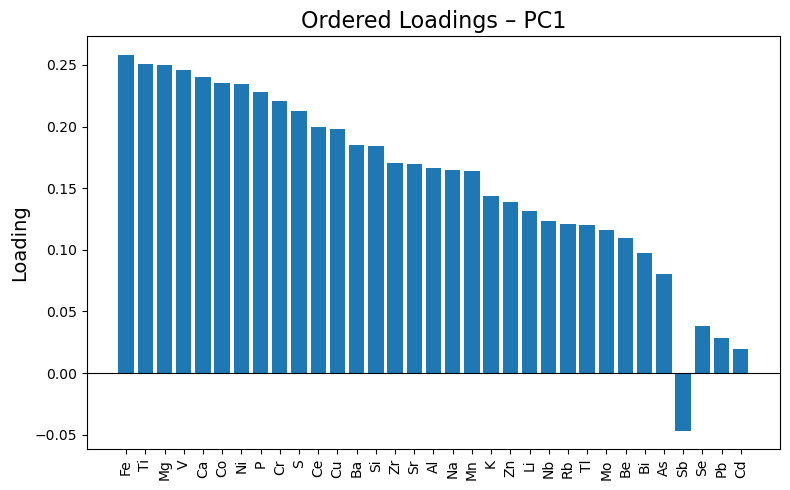

In [69]:
plot_ordered_loadings(loadings_df, pc=1, absolute=True)

C:\Users\bruno\AppData\Local\Temp\ipykernel_26520\915295027.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ordered.index, rotation=90)


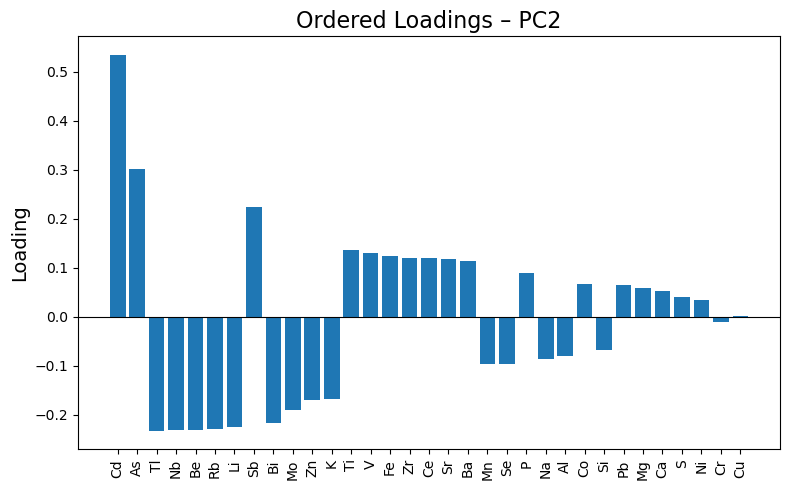

In [70]:
plot_ordered_loadings(loadings_df, pc=2, absolute=True)

C:\Users\bruno\AppData\Local\Temp\ipykernel_26520\915295027.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ordered.index, rotation=90)


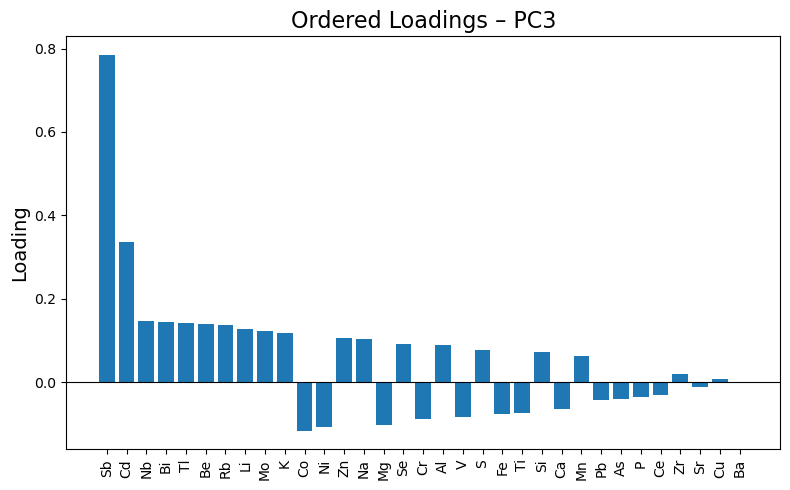

In [71]:
plot_ordered_loadings(loadings_df, pc=3, absolute=True)

C:\Users\bruno\AppData\Local\Temp\ipykernel_26520\915295027.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ordered.index, rotation=90)


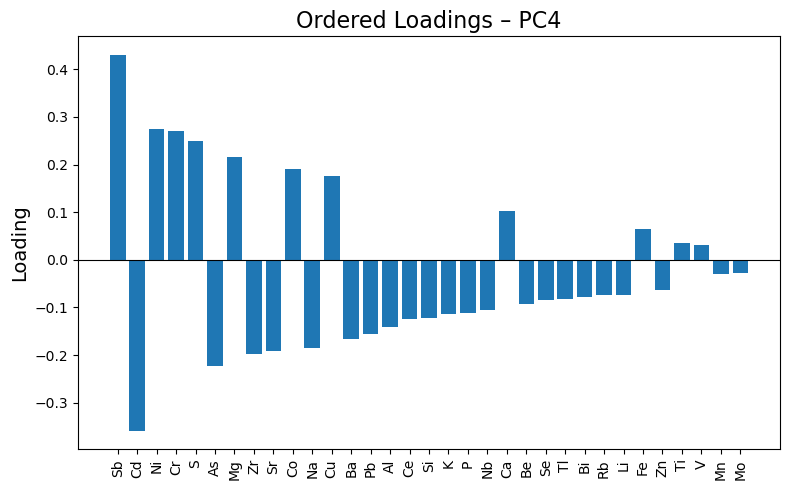

In [72]:
plot_ordered_loadings(loadings_df, pc=4, absolute=True)

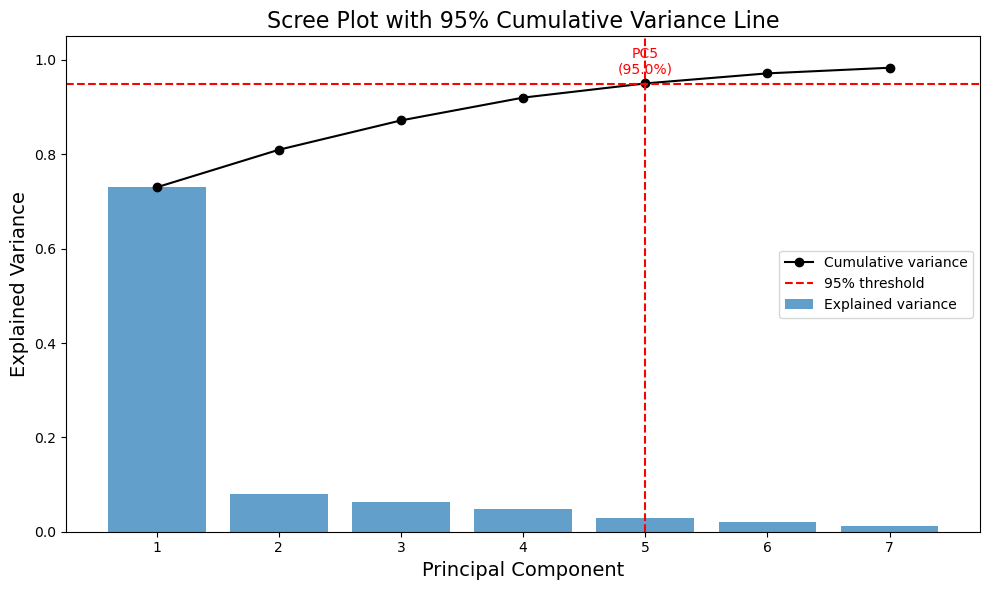

In [73]:

def scree_plot(pca, threshold=0.95, figsize=(10,6)):
    """
    Creates a scree plot with explained variance and cumulative variance.
    Adds a horizontal line marking the given cumulative threshold (0.95).
    """

    evr = pca.explained_variance_ratio_
    cum_evr = np.cumsum(evr)

    # component numbers (1-based)
    components = np.arange(1, len(evr) + 1)

    # find first component where cumulative variance exceeds threshold
    k = np.argmax(cum_evr >= threshold) + 1

    fig, ax = plt.subplots(figsize=figsize)

    # bar plot of individual explained variance
    ax.bar(components, evr, alpha=0.7, label='Explained variance')

    # cumulative explained variance line
    ax.plot(components, cum_evr, marker='o', color='black', label='Cumulative variance')

    # horizontal threshold line
    ax.axhline(threshold, color='red', linestyle='--', label=f'{int(threshold*100)}% threshold')

    # vertical line at the component index where threshold is reached
    ax.axvline(k, color='red', linestyle='--')

    # label that point
    ax.text(k, cum_evr[k-1] + 0.02,
            f'PC{k}\n({cum_evr[k-1]*100:.1f}%)',
            ha='center', color='red')

    ax.set_xlabel("Principal Component", fontsize=14)
    ax.set_ylabel("Explained Variance", fontsize=14)
    ax.set_title("Scree Plot with 95% Cumulative Variance Line", fontsize=16)
    ax.set_ylim(0, 1.05)
    ax.legend()

    plt.tight_layout()

scree_plot(pca, threshold=0.95)

# Some correlation

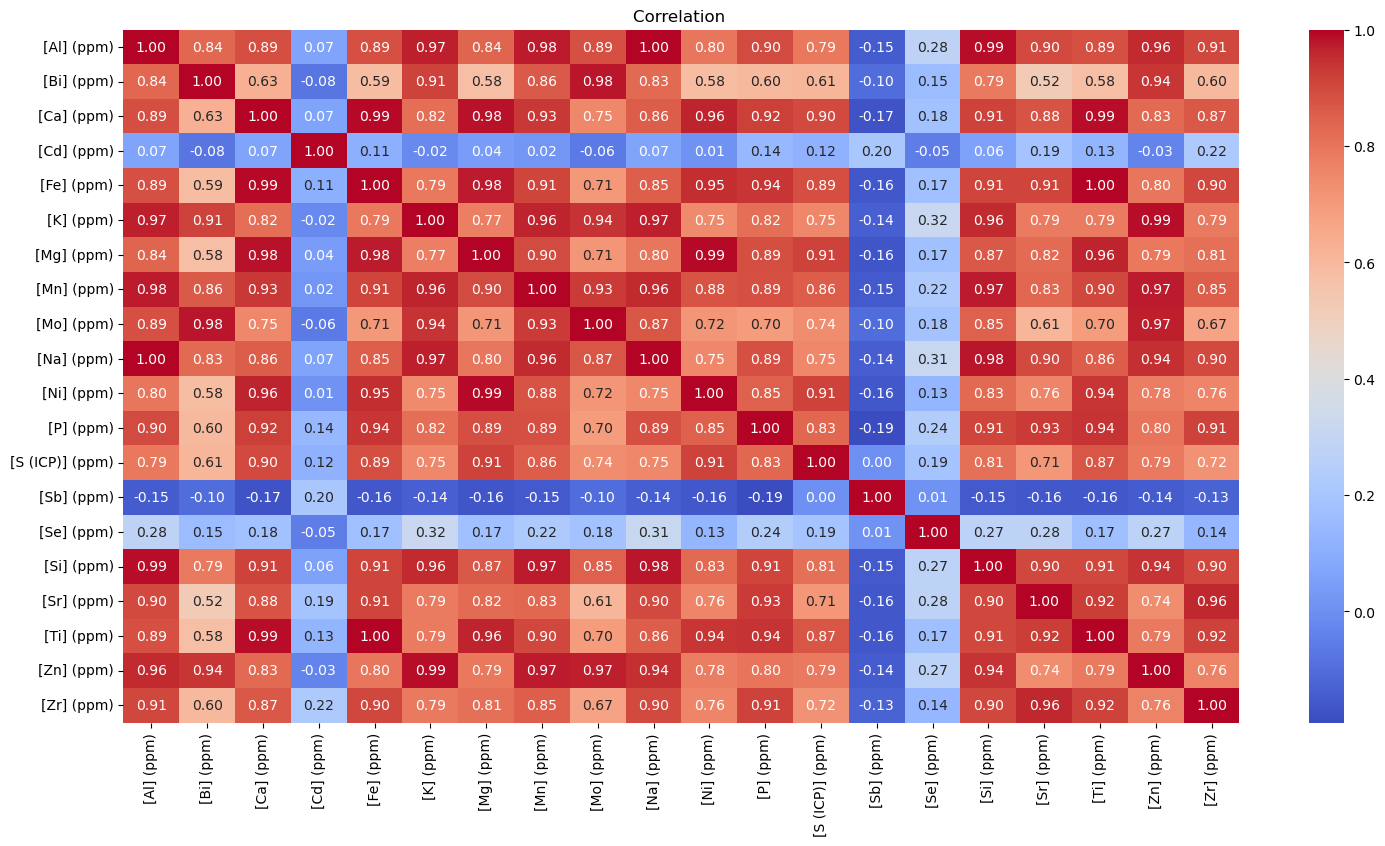

In [74]:
temp_cols = ppm_cols.copy()

# Compute correlation matrices: Return Pearson product-moment correlation coefficients.
corr_norm = np.corrcoef(df[temp_cols], rowvar=False)
corr_norm = corr_norm
fig, ax = plt.subplots(1,1,figsize=(18,9))
ax.set_title("Correlation ")
sns.heatmap(corr_norm, ax=ax, annot=True,xticklabels= temp_cols,yticklabels=temp_cols, fmt=".2f", cmap="coolwarm")
plt.show()

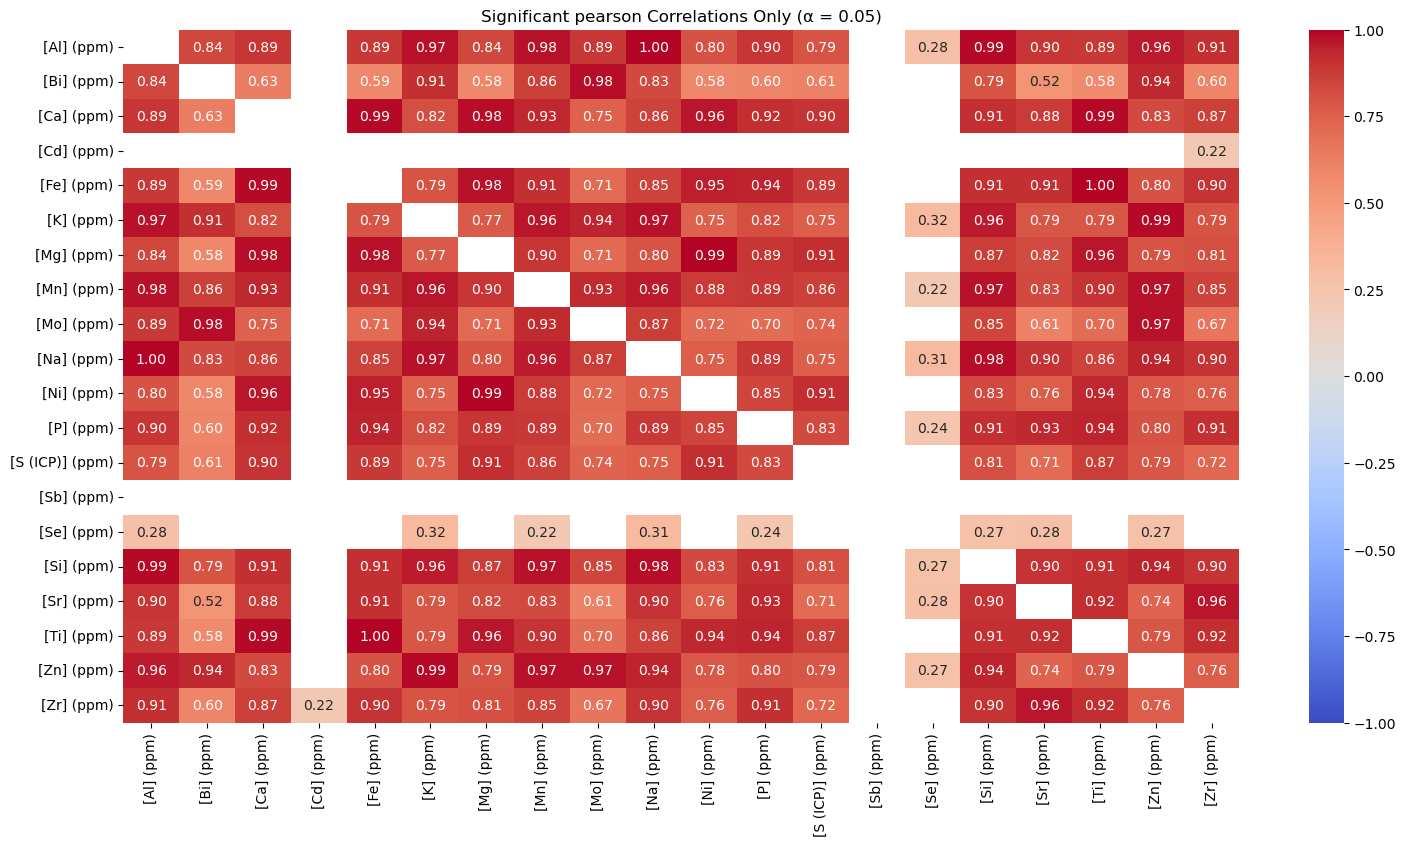

In [75]:
import itertools
temp_cols = ppm_cols.copy()
alpha = 0.05
threshold = 0.2
significant = {}

for col1, col2 in itertools.combinations(temp_cols, 2):

    # Compute Spearman correlation
    # rho, pval = stats.spearmanr(df[col1], df[col2], nan_policy='omit')
    rho, pval = stats.pearsonr(df[col1], df[col2])

    # Check significance
    if pval < alpha:
        if rho > threshold or rho < -threshold:
            significant[(col1, col2)] = {"rho": rho, "p": pval}



n = len(temp_cols)

# Empty matrix of NaN
sig_corr = pd.DataFrame(np.nan, index=temp_cols, columns=temp_cols)

# Fill only significant correlations
for (c1, c2), vals in significant.items():
    sig_corr.loc[c1, c2] = vals["rho"]
    sig_corr.loc[c2, c1] = vals["rho"]   # make symmetric


plt.figure(figsize=(18,9))
sns.heatmap(sig_corr, annot=True,  vmin=-1, vmax=1, fmt=".2f", cmap="coolwarm")
plt.title(f"Significant pearson Correlations Only (α = {alpha})")
plt.show()


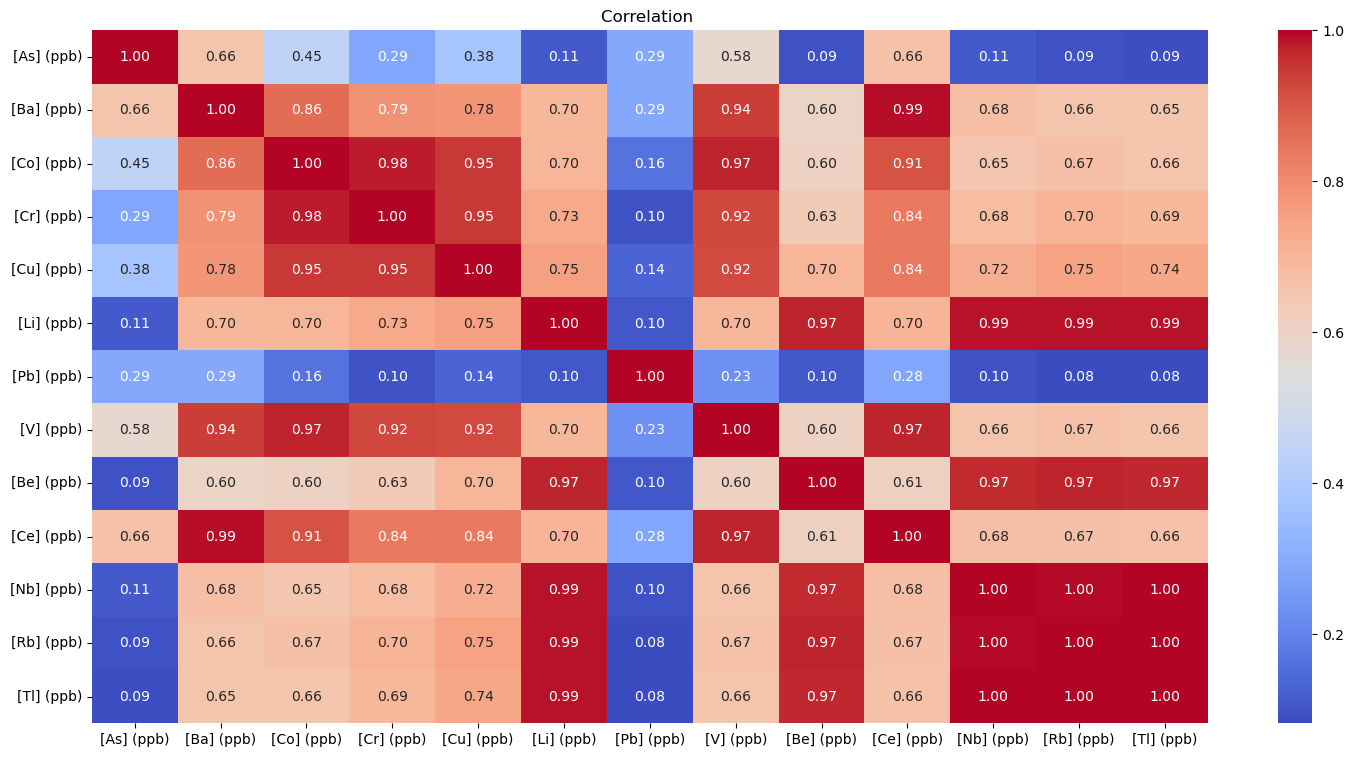

In [76]:
temp_cols = ppb_cols.copy()
# Compute correlation matrices: Return Pearson product-moment correlation coefficients.
corr_norm = np.corrcoef(df[temp_cols], rowvar=False)

fig, ax = plt.subplots(1,1,figsize=(18,9))
ax.set_title("Correlation ")
sns.heatmap(corr_norm, ax=ax, annot=True,xticklabels= temp_cols,yticklabels=temp_cols, fmt=".2f",cmap="coolwarm")
plt.show()

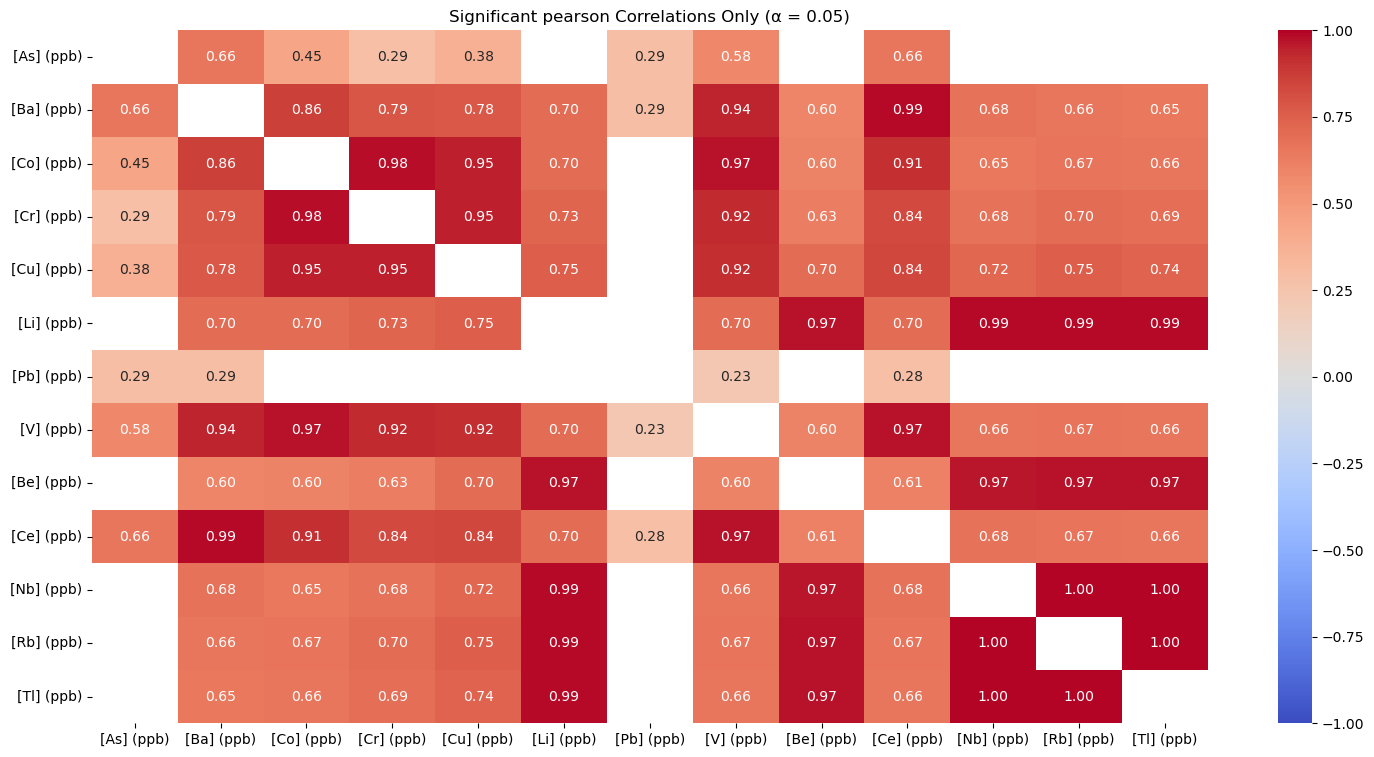

In [77]:
import itertools
temp_cols = ppb_cols.copy()
alpha = 0.05
threshold = 0.2
significant = {}

for col1, col2 in itertools.combinations(temp_cols, 2):

    # Compute Spearman correlation
    # rho, pval = stats.spearmanr(df[col1], df[col2], nan_policy='omit')
    rho, pval = stats.pearsonr(df[col1], df[col2])

    # Check significance
    if pval < alpha:
        if rho > threshold or rho < -threshold:
            significant[(col1, col2)] = {"rho": rho, "p": pval}



n = len(temp_cols)

# Empty matrix of NaN
sig_corr = pd.DataFrame(np.nan, index=temp_cols, columns=temp_cols)

# Fill only significant correlations
for (c1, c2), vals in significant.items():
    sig_corr.loc[c1, c2] = vals["rho"]
    sig_corr.loc[c2, c1] = vals["rho"]   # make symmetric


plt.figure(figsize=(18,9))
sns.heatmap(sig_corr, annot=True,  vmin=-1, vmax=1, fmt=".2f", cmap="coolwarm")
plt.title(f"Significant pearson Correlations Only (α = {alpha})")
plt.show()


## Correlation interpretation??

Not a direct geological interpretation, but it reflects what is being deposited together >> Li and Nb do not share a similar z/r or partitions, but are both associated with the pegmatite, and are probably becoming dust together, causing a joint deposition

Cu, V, Pb are no ocurring withing the pegmatite it seems,as they are not correlated to Li for example

# For future data: Data levelling

In [ ]:
# def level_data(dataframe,col,method):

#     leveled_name = col+'_levelled'
#     df1 = dataframe.query('Year == 1988').copy()
#     df2 = dataframe.query('Year == 1989').copy()

#     if method == 'MedianShift':


#         median1 = df1[col].median()
#         median2 = df2[col].median()
#         df1.loc[:, leveled_name] = (
#             (df1[col] - median1)) + median2

#     elif method == 'ZRobust':
#         MEDIAN1 = df1[col].median()
#         MEDIAN2 = df2[col].median()

#         MAD1 = stats.median_abs_deviation(df1[col])
#         MAD2 = stats.median_abs_deviation(df2[col])


#         # 1. Direct Leveling Calculation on df1
#         # (Standardize df1 using its own stats, then rescale to df2's stats)
#         df1.loc[:, leveled_name] = (
#             (df1[col] - MEDIAN1) / MAD1 * MAD2
#         ) + MEDIAN2
#     elif method == 'ZScore':
#         mean1 = df1[col].mean()
#         mean2 = df2[col].mean()

#         std1 = df1[col].std()
#         std2 = df2[col].std()


#         # 1. Direct Leveling Calculation on df1
#         # (Standardize df1 using its own stats, then rescale to df2's stats)
#         df1.loc[:, leveled_name] = (
#             (df1[col] - mean1) / std1 * std2
#         ) + mean2
#     else:
#         raise ValueError 

#     df2.loc[:, leveled_name] = df2[col]

#     # 3. Concatenate the results
#     leveled_df = pd.concat([df1, df2])

        
#     fig, ax = plt.subplots(1, 2, figsize=(12, 6)) # Increased figure size

#     color_palette = 'Set1' 

#     # Plot 1: Original Data
#     sns.boxplot(x='Year', y=col, data=df, ax=ax[0], hue='Year', palette=color_palette)
#     ax[0].set_title('Original Data Distribution')
#     ax[0].set_ylabel(col + ' (Original)')
#     ax[0].grid(True, linestyle='--', alpha=0.6)

#     # Plot 2: Leveled Data
#     # Use the same palette name to ensure consistency across both plots
#     sns.boxplot(x='Year', y=leveled_name, data=leveled_df, ax=ax[1], hue='Year', palette=color_palette)
#     ax[1].set_title(f'Leveled Data Distribution ({method})')
#     ax[1].set_ylabel(leveled_name + ' (Leveled)')
#     ax[1].grid(True, linestyle='--', alpha=0.6)

#     # Overall settings
#     # fig.suptitle('Comparison of Original vs. Leveled Data Distributions', fontsize=14)
#     plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to make room for suptitle

#     # Save the plot instead of showing it
#     plt.savefig(f'{col}_original_vs_leveled_{method}_boxplot.png')

#     return leveled_df
# level_df = df.copy()
# for (element,method) in leveling.items():
    
#     level_df = level_data(level_df,element,method)